# Adaptive Restaurant Seating and Queue Management Using RL

This notebook explains the restaurant environment, policies and feature extractors,
runs one development example, and displays results from the completed experiments.

**Run All** constructs 20 untrained DQN/PPO variants, runs Best-fit on one
Dinner/Normal episode with seed **20000**, and displays the embedded tables and
figures. It needs no project folder, CSV files or checkpoints. Keep
`RUN_FULL_TRAINING=False`; the final test seeds **12000–12199** are never run.

Expand the collapsed code cells to read the implementation. Sections A–F cover
the implementation, G the example, H the disabled training recipe, I–J recorded
results, K interpretation, and L references and AI acknowledgement.


### Dependencies

Run All uses NumPy, pandas, matplotlib, Gymnasium, PyTorch, Stable-Baselines3 and
sb3-contrib. The setup cell prints available versions and reports any missing
packages. Installation is an explicit, optional action, never part of normal
execution. The formal RL runtime used Python 3.12.10, NumPy 2.5.3, Gymnasium 1.3.0,
PyTorch 2.14.0+cpu, SB3 2.9.0, sb3-contrib 2.9.0 and cloudpickle 3.1.2.

In [1]:
# Optional Colab setup: uncomment only if packages are missing, then restart the kernel.
# %pip install numpy pandas matplotlib gymnasium torch stable-baselines3==2.9.0 sb3-contrib==2.9.0


In [2]:
from __future__ import annotations
import importlib.metadata as metadata
import platform
packages = ["numpy", "pandas", "matplotlib", "gymnasium", "torch",
            "stable-baselines3", "sb3-contrib", "cloudpickle"]
print("Python:", platform.python_version())
missing = []
for package in packages:
    try:
        print(f"{package}: {metadata.version(package)}")
    except metadata.PackageNotFoundError:
        print(f"{package}: MISSING")
        missing.append(package)
if missing:
    raise ImportError("Install missing packages explicitly before Run All: " + ", ".join(missing))

import hashlib
import math
from dataclasses import dataclass
from typing import Final, TypeAlias, NamedTuple
from io import StringIO
from statistics import mean
from pathlib import Path  # Used only by the opt-in training recipe.
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import gymnasium as gym
from gymnasium import spaces
import torch as th
from torch import nn
from stable_baselines3 import DQN
from stable_baselines3.common.torch_layers import BaseFeaturesExtractor
from stable_baselines3.common.callbacks import BaseCallback
from sb3_contrib import MaskablePPO
from IPython.display import display
pd.set_option("display.max_rows", 80)
pd.set_option("display.max_columns", 14)
pd.set_option("display.float_format", lambda x: f"{x:.4f}")
plt.rcParams.update({"figure.dpi": 120, "font.size": 10})
RUN_FULL_TRAINING = False


Python: 3.13.16
numpy: 2.5.3
pandas: 3.0.5
matplotlib: 3.11.2
gymnasium: 1.3.0
torch: 2.14.1
stable-baselines3: 2.9.0
sb3-contrib: 2.9.0
cloudpickle: 3.1.2


## A. Environment constants and entities

These definitions match the `restaurant_rl` modules, with imports shared across
the notebook. Only constants needed here are included; both meal configurations
are retained.

The restaurant has 12 tables, a 12-party queue, a temporary arrival buffer,
51 observation features and 12 actions. Tables and parties validate their state
when created.


In [3]:
TickBand: TypeAlias = tuple[int, int | None, float]

WeightedValue: TypeAlias = tuple[float, float]

@dataclass(frozen=True)
class MealConfig:
    """Canonical parameters for one meal period, expressed in ticks."""

    name: str
    opening_tick_of_day: int
    closing_tick_of_day: int
    base_arrival_curve: tuple[TickBand, ...]
    party_size_probabilities: tuple[float, ...]
    mean_dining_ticks: tuple[int, ...]
    dining_multiplier_distribution: tuple[WeightedValue, ...]
    abandonment_hazard: tuple[TickBand, ...]
    abandonment_time_multipliers: tuple[TickBand, ...]
    abandonment_probability_cap: float

    @property
    def arrival_window_ticks(self) -> int:
        """Number of five-minute arrival intervals in this meal period."""

        return self.closing_tick_of_day - self.opening_tick_of_day

# Table order is fixed: positions also identify the first observation block.
TABLE_CAPACITIES: Final[tuple[int, ...]] = (
    2,
    2,
    2,
    2,
    4,
    4,
    4,
    4,
    6,
    6,
    6,
    8,
)

TABLE_IDS: Final[tuple[int, ...]] = tuple(range(1, len(TABLE_CAPACITIES) + 1))

CANONICAL_TABLE_CAPACITIES: Final[frozenset[int]] = frozenset(TABLE_CAPACITIES)

TABLE_CAPACITY_COUNTS: Final[dict[int, int]] = {
    capacity: TABLE_CAPACITIES.count(capacity)
    for capacity in sorted(CANONICAL_TABLE_CAPACITIES)
}

TABLE_COUNT: Final = len(TABLE_CAPACITIES)

SUPPORTED_PARTY_SIZES: Final[tuple[int, ...]] = tuple(range(1, 9))

QUEUE_CAPACITY: Final = 12

# Each position is an action ID for (party size, table capacity); ID 11 advances time.
SEATING_ACTION_PAIRS: Final[tuple[tuple[int, int], ...]] = (
    (1, 2),
    (1, 4),
    (2, 2),
    (2, 4),
    (3, 4),
    (4, 4),
    (4, 6),
    (5, 6),
    (6, 6),
    (7, 8),
    (8, 8),
)

ACTION_TO_SEATING: Final[dict[int, tuple[int, int]]] = dict(
    enumerate(SEATING_ACTION_PAIRS)
)

SEATING_TO_ACTION: Final[dict[tuple[int, int], int]] = {
    pair: action_id for action_id, pair in ACTION_TO_SEATING.items()
}

END_TICK_ACTION_ID: Final = 11

ACTION_COUNT: Final = 12

# Observation blocks and normalisation limits must stay compatible with saved policies.
TABLE_OBSERVATION_FEATURES: Final = 12

QUEUE_SLOT_COUNT: Final = 12

QUEUE_FEATURES_PER_SLOT: Final = 2

QUEUE_OBSERVATION_FEATURES: Final = QUEUE_SLOT_COUNT * QUEUE_FEATURES_PER_SLOT

ARRIVAL_BUFFER_OBSERVATION_FEATURES: Final = 8

SERVICE_PROGRESS_OBSERVATION_FEATURES: Final = 1

DEMAND_SCENARIO_OBSERVATION_FEATURES: Final = 4

MEAL_OBSERVATION_FEATURES: Final = 2

OBSERVATION_BLOCK_SIZES: Final[tuple[tuple[str, int], ...]] = (
    ("tables", TABLE_OBSERVATION_FEATURES),
    ("queue", QUEUE_OBSERVATION_FEATURES),
    ("arrival_buffer", ARRIVAL_BUFFER_OBSERVATION_FEATURES),
    ("service_progress", SERVICE_PROGRESS_OBSERVATION_FEATURES),
    ("demand_scenario", DEMAND_SCENARIO_OBSERVATION_FEATURES),
    ("meal", MEAL_OBSERVATION_FEATURES),
)

OBSERVATION_DIMENSION: Final = 51

PARTY_SIZE_NORMALIZATION_DIVISOR: Final = 8

WAITING_TICK_NORMALIZATION_CAP: Final = 24

MAX_TABLE_REMAINING_TICKS: Final = 36

# Penalties count people, not parties; seating itself has no immediate reward.
WAITED_PERSON_REWARD: Final = -0.1

LOST_PERSON_REWARD: Final = -1.2

SEATING_ASSIGNMENT_REWARD: Final = 0.0

END_TICK_FIXED_REWARD: Final = 0.0

DISCOUNT_FACTOR: Final = 1.0

DEMAND_SCENARIO_MULTIPLIERS: Final[dict[str, float]] = {
    "off_peak": 0.75,
    "normal": 1.00,
    "peak": 1.25,
    "super_peak": 1.50,
}

# Rate and hazard bands use [start, end) tick ranges; None means no upper bound.
LUNCH_CONFIG: Final = MealConfig(
    name="lunch",
    opening_tick_of_day=132,
    closing_tick_of_day=174,
    base_arrival_curve=(
        (0, 6, 0.40),
        (6, 12, 0.75),
        (12, 24, 1.20),
        (24, 30, 1.00),
        (30, 36, 0.60),
        (36, 42, 0.30),
    ),
    party_size_probabilities=(0.30, 0.40, 0.15, 0.10, 0.02, 0.02, 0.005, 0.005),
    mean_dining_ticks=(6, 9, 12, 15, 17, 19, 21, 23),
    dining_multiplier_distribution=(
        (0.70, 0.03),
        (0.85, 0.17),
        (0.95, 0.25),
        (1.00, 0.25),
        (1.10, 0.18),
        (1.25, 0.12),
    ),
    abandonment_hazard=(
        (0, 2, 0.00),
        (2, 3, 0.03),
        (3, 4, 0.08),
        (4, 6, 0.15),
        (6, 9, 0.30),
        (9, None, 0.50),
    ),
    abandonment_time_multipliers=(
        (0, 12, 0.8),
        (12, 24, 1.0),
        (24, 36, 1.3),
        (36, None, 1.6),
    ),
    abandonment_probability_cap=0.65,
)

DINNER_CONFIG: Final = MealConfig(
    name="dinner",
    opening_tick_of_day=204,
    closing_tick_of_day=264,
    base_arrival_curve=(
        (0, 12, 0.35),
        (12, 24, 0.50),
        (24, 48, 0.65),
        (48, 60, 0.45),
    ),
    party_size_probabilities=(0.15, 0.30, 0.15, 0.20, 0.07, 0.08, 0.02, 0.03),
    mean_dining_ticks=(9, 15, 18, 18, 21, 24, 27, 30),
    dining_multiplier_distribution=(
        (0.85, 0.05),
        (0.90, 0.24),
        (0.95, 0.13),
        (1.00, 0.25),
        (1.05, 0.10),
        (1.10, 0.08),
        (1.15, 0.10),
        (1.20, 0.05),
    ),
    abandonment_hazard=(
        (0, 3, 0.00),
        (3, 6, 0.02),
        (6, 9, 0.05),
        (9, 12, 0.10),
        (12, 15, 0.18),
        (15, 18, 0.28),
        (18, None, 0.40),
    ),
    abandonment_time_multipliers=(
        (0, 24, 0.8),
        (24, 36, 1.0),
        (36, 48, 1.6),
        (48, None, 2.0),
    ),
    abandonment_probability_cap=0.60,
)

MEAL_CONFIGS: Final[dict[str, MealConfig]] = {
    LUNCH_CONFIG.name: LUNCH_CONFIG,
    DINNER_CONFIG.name: DINNER_CONFIG,
}


In [4]:
PartyId: TypeAlias = tuple[int, int]

def _validate_party_id(party_id: PartyId) -> None:
    """Require a non-negative arrival tick and within-interval index for stable party keys."""
    if (
        not isinstance(party_id, tuple)
        or len(party_id) != 2
        or any(type(part) is not int or part < 0 for part in party_id)
    ):
        raise ValueError(
            "party_id must be (arrival_tick, arrival_index) with non-negative integers"
        )

@dataclass
class Table:
    """One fixed restaurant table and its current occupancy state."""

    table_id: int
    capacity: int
    assigned_party_id: PartyId | None = None
    remaining_ticks: int = 0

    def __post_init__(self) -> None:
        """Check fixed table capacities and agreement between occupancy and remaining dining time."""
        if type(self.table_id) is not int or self.table_id not in TABLE_IDS:
            raise ValueError(f"table_id must be one of {TABLE_IDS}")
        expected_capacity = TABLE_CAPACITIES[self.table_id - 1]
        if type(self.capacity) is not int or self.capacity != expected_capacity:
            raise ValueError(
                f"table {self.table_id} must have canonical capacity "
                f"{expected_capacity}"
            )
        if type(self.remaining_ticks) is not int or self.remaining_ticks < 0:
            raise ValueError("remaining_ticks must be a non-negative integer")
        if self.assigned_party_id is None:
            if self.remaining_ticks != 0:
                raise ValueError("a free table must have zero remaining_ticks")
        else:
            _validate_party_id(self.assigned_party_id)
            if self.remaining_ticks == 0:
                raise ValueError("an occupied table must have positive remaining_ticks")

    @property
    def is_occupied(self) -> bool:
        """Whether a party is currently assigned to this table."""

        return self.assigned_party_id is not None

@dataclass
class CustomerParty:
    """A generated customer party waiting to be seated."""

    party_id: PartyId
    size: int
    waiting_ticks: int = 0

    def __post_init__(self) -> None:
        """Validate the party identity, supported size and non-negative waiting time."""
        _validate_party_id(self.party_id)
        if type(self.size) is not int or self.size not in SUPPORTED_PARTY_SIZES:
            raise ValueError(
                f"size must be one of the supported party sizes {SUPPORTED_PARTY_SIZES}"
            )
        if type(self.waiting_ticks) is not int or self.waiting_ticks < 0:
            raise ValueError("waiting_ticks must be a non-negative integer")


### Reproducible randomness

Arrival counts, party sizes, dining durations, overflow and abandonment use stable
keys. The environment retains the original draw keys and update order.

In [5]:
def stable_rng(*key_parts: object) -> np.random.Generator:
    """Create a NumPy generator from a stable, process-independent key."""

    # Hash explicit event keys so draws do not depend on Python's process hash or call order.
    key = ":".join(str(part) for part in key_parts).encode("utf-8")
    stable_seed = int.from_bytes(hashlib.sha256(key).digest()[:8], "big")
    return np.random.default_rng(stable_seed)

def keyed_dining_multiplier(
    episode_seed: int,
    party_id: tuple[int, int],
    distribution: tuple[WeightedValue, ...],
) -> float:
    """Choose a dining multiplier from a stable party-specific key."""

    random_generator = stable_rng(
        episode_seed,
        party_id[0],
        party_id[1],
        "dining_duration",
    )
    multipliers, probabilities = zip(*distribution)
    return float(random_generator.choice(multipliers, p=probabilities))


## B. RestaurantEnv

Seating takes no simulated time. END_TICK resolves the arrival buffer, advances
time and table timers, increments waiting, applies abandonment, and generates
arrivals for the completed interval, in that order.

Reward penalises waiting people and lost customers. An episode ends after closing
when the queue and buffer are empty; seated diners may still be present.


In [6]:
class RestaurantEnv(gym.Env):
    """Canonical restaurant state with zero-time seating actions."""

    def __init__(self, meal: str, demand_scenario: str) -> None:
        """Validate the meal and demand level, then prepare the spaces and opening state."""
        super().__init__()

        if meal not in MEAL_CONFIGS:
            raise ValueError(f"meal must be one of {tuple(MEAL_CONFIGS)}")
        if demand_scenario not in DEMAND_SCENARIO_MULTIPLIERS:
            raise ValueError(
                "demand_scenario must be one of "
                f"{tuple(DEMAND_SCENARIO_MULTIPLIERS)}"
            )

        self.meal = meal
        self.meal_config = MEAL_CONFIGS[meal]
        self.demand_scenario = demand_scenario

        self.action_space = spaces.Discrete(ACTION_COUNT)
        self.observation_space = spaces.Box(
            low=0.0,
            high=1.0,
            shape=(OBSERVATION_DIMENSION,),
            dtype=np.float32,
        )

        self.episode_seed: int | None = None
        self._set_opening_state()

    def _set_opening_state(self) -> None:
        """Restore the canonical empty restaurant state at meal opening."""

        self.tables = [
            Table(table_id=table_id, capacity=capacity)
            for table_id, capacity in zip(TABLE_IDS, TABLE_CAPACITIES)
        ]
        self.waiting_queue = []
        self.arrival_buffer = []
        self.current_tick = self.meal_config.opening_tick_of_day
        self.arrivals_open = True

    def reset(self, *, seed=None, options=None):
        """Reset to meal opening without generating or seating customers."""

        super().reset(seed=seed)
        if seed is None:
            self.episode_seed = int(
                self.np_random.integers(0, np.iinfo(np.int64).max)
            )
        else:
            self.episode_seed = int(seed)
        self._set_opening_state()
        observation = self._get_observation()
        info = {
            "meal": self.meal,
            "demand_scenario": self.demand_scenario,
            "action_mask": self._get_action_mask(),
        }
        return observation, info

    def _get_action_mask(self) -> np.ndarray:
        """Return the current legality of all seating actions and END_TICK."""

        # A seating action needs both a matching party and a free table of its listed capacity.
        mask = np.zeros(ACTION_COUNT, dtype=np.bool_)
        for action_id, (party_size, table_capacity) in ACTION_TO_SEATING.items():
            has_party = any(
                party.size == party_size
                for party in self.waiting_queue + self.arrival_buffer
            )
            has_table = any(
                table.capacity == table_capacity and not table.is_occupied
                for table in self.tables
            )
            mask[action_id] = has_party and has_table

        mask[END_TICK_ACTION_ID] = True
        return mask

    def _select_party(
        self,
        party_size: int,
    ) -> tuple[CustomerParty, list[CustomerParty]]:
        """Select queue-first, then apply the canonical party tie-breaks."""

        # Existing queue parties get the seat before same-size fresh arrivals.
        queued = [
            party for party in self.waiting_queue if party.size == party_size
        ]
        if queued:
            party = min(
                queued,
                key=lambda item: (-item.waiting_ticks, item.party_id),
            )
            return party, self.waiting_queue

        buffered = [
            party for party in self.arrival_buffer if party.size == party_size
        ]
        if buffered:
            party = min(buffered, key=lambda item: item.party_id)
            return party, self.arrival_buffer

        raise AssertionError("valid seating action has no matching party")

    def _select_table(self, table_capacity: int) -> Table:
        """Select the lowest-ID free table with the requested capacity."""

        available = [
            table
            for table in self.tables
            if table.capacity == table_capacity and not table.is_occupied
        ]
        if not available:
            raise AssertionError("valid seating action has no matching table")
        return min(available, key=lambda table: table.table_id)

    def _get_dining_duration(self, party: CustomerParty) -> int:
        """Realise a keyed duration, rounded half-up to a five-minute tick."""

        if self.episode_seed is None:
            raise RuntimeError("reset() must be called before step()")

        mean_ticks = self.meal_config.mean_dining_ticks[party.size - 1]
        multiplier = keyed_dining_multiplier(
            self.episode_seed,
            party.party_id,
            self.meal_config.dining_multiplier_distribution,
        )
        duration = int(mean_ticks * multiplier + 0.5)
        if not 1 <= duration <= MAX_TABLE_REMAINING_TICKS:
            raise AssertionError("dining duration is outside the supported range")
        return duration

    def _is_naturally_terminated(self) -> bool:
        """End after closing when the queue and arrival buffer are empty.

        Seated diners may remain because they need no further seating decisions.
        """

        return (
            not self.arrivals_open
            and not self.waiting_queue
            and not self.arrival_buffer
        )

    def _resolve_arrival_buffer(self) -> int:
        """Move buffered parties into free queue slots and return balked people."""

        if len(self.waiting_queue) > QUEUE_CAPACITY:
            raise AssertionError("waiting queue exceeds canonical capacity")
        if self.episode_seed is None:
            raise RuntimeError("reset() must be called before step()")

        # When arrivals exceed queue space, rank them by stable party-specific draws.
        free_slots = QUEUE_CAPACITY - len(self.waiting_queue)
        ordered_buffer = list(self.arrival_buffer)
        if len(ordered_buffer) > free_slots:
            ordered_buffer.sort(
                key=lambda party: (
                    stable_rng(
                        self.episode_seed,
                        party.party_id[0],
                        party.party_id[1],
                        self.current_tick,
                        "overflow",
                    ).random(),
                    party.party_id,
                )
            )

        # Admit the selected parties and count everyone else as balked; no buffer carries over.
        admitted = ordered_buffer[:free_slots]
        balked = ordered_buffer[free_slots:]
        self.waiting_queue.extend(admitted)
        self.arrival_buffer = []
        return sum(party.size for party in balked)

    def _advance_tables(self) -> None:
        """Advance occupied dining times by one tick and release completions."""

        for table in self.tables:
            if table.is_occupied:
                table.remaining_ticks -= 1
                if table.remaining_ticks == 0:
                    table.assigned_party_id = None
            if table.remaining_ticks < 0:
                raise AssertionError("table remaining_ticks cannot be negative")

    def _get_abandonment_probability(self, party: CustomerParty) -> float:
        """Return the canonical hazard after this tick's waiting increment."""

        # Choose the waiting-time hazard using the updated number of ticks waited.
        base_hazard = None
        for start, end, hazard in self.meal_config.abandonment_hazard:
            if start <= party.waiting_ticks and (
                end is None or party.waiting_ticks < end
            ):
                base_hazard = hazard
                break

        ticks_since_open = self.current_tick - self.meal_config.opening_tick_of_day
        # Scale that hazard by time since opening, then apply the configured cap.
        time_multiplier = None
        for start, end, multiplier in self.meal_config.abandonment_time_multipliers:
            if start <= ticks_since_open and (
                end is None or ticks_since_open < end
            ):
                time_multiplier = multiplier
                break

        if base_hazard is None or time_multiplier is None:
            raise AssertionError("abandonment configuration does not cover state")
        return min(
            base_hazard * time_multiplier,
            self.meal_config.abandonment_probability_cap,
        )

    def _apply_abandonment(self) -> int:
        """Remove keyed abandoning parties and return abandoned people."""

        if self.episode_seed is None:
            raise RuntimeError("reset() must be called before step()")

        # Draw separately for each party and waiting age, preserving survivor order.
        remaining_parties: list[CustomerParty] = []
        abandoned_persons = 0
        for party in self.waiting_queue:
            probability = self._get_abandonment_probability(party)
            draw = stable_rng(
                self.episode_seed,
                party.party_id[0],
                party.party_id[1],
                party.waiting_ticks,
                "abandon",
            ).random()
            if draw < probability:
                abandoned_persons += party.size
            else:
                remaining_parties.append(party)

        self.waiting_queue = remaining_parties
        return abandoned_persons

    def _generate_arrivals(self, interval_tick: int) -> list[CustomerParty]:
        """Generate the keyed arrivals for one completed arrival interval."""

        if self.episode_seed is None:
            raise RuntimeError("reset() must be called before step()")
        if not (
            self.meal_config.opening_tick_of_day
            <= interval_tick
            < self.meal_config.closing_tick_of_day
        ):
            return []

        # Use the completed interval to choose the arrival rate, including the last open interval.
        interval_offset = interval_tick - self.meal_config.opening_tick_of_day
        base_rate = None
        for start, end, rate in self.meal_config.base_arrival_curve:
            if start <= interval_offset and (
                end is None or interval_offset < end
            ):
                base_rate = rate
                break
        if base_rate is None:
            raise AssertionError("arrival curve does not cover arrival interval")

        arrival_rate = (
            base_rate * DEMAND_SCENARIO_MULTIPLIERS[self.demand_scenario]
        )
        # Sample the number of parties from a count-specific random stream.
        arrival_count = int(
            stable_rng(
                self.episode_seed,
                self.meal,
                self.demand_scenario,
                interval_tick,
                "arrival_count",
            ).poisson(arrival_rate)
        )

        # Give each arrival its own size draw and stable (interval, index) identity.
        arrivals: list[CustomerParty] = []
        for arrival_index in range(arrival_count):
            party_size = int(
                stable_rng(
                    self.episode_seed,
                    self.meal,
                    self.demand_scenario,
                    interval_tick,
                    arrival_index,
                    "party_size",
                ).choice(
                    SUPPORTED_PARTY_SIZES,
                    p=self.meal_config.party_size_probabilities,
                )
            )
            arrivals.append(
                CustomerParty(
                    party_id=(interval_tick, arrival_index),
                    size=party_size,
                )
            )
        return arrivals

    def _step_end_tick(self):
        """Resolve overflow, advance time, apply waiting and abandonment, then add arrivals."""

        if self.episode_seed is None:
            raise RuntimeError("reset() must be called before step()")

        # Resolve unseated arrivals before advancing time or freeing tables.
        balked_persons = self._resolve_arrival_buffer()
        # Advance one five-minute interval and release tables whose dining time has ended.
        completed_interval_tick = self.current_tick
        self.current_tick += 1
        self._advance_tables()

        # Increase every queued party's wait before checking abandonment.
        for party in self.waiting_queue:
            party.waiting_ticks += 1
        # Parties abandoning now still waited through the completed interval.
        waited_persons = sum(party.size for party in self.waiting_queue)
        abandoned_persons = self._apply_abandonment()

        # Add arrivals for the completed interval after waiting and abandonment are settled.
        self.arrival_buffer = self._generate_arrivals(completed_interval_tick)
        self.arrivals_open = (
            self.current_tick < self.meal_config.closing_tick_of_day
        )

        # Charge waiting and lost-person penalties once for this interval.
        lost_persons = abandoned_persons + balked_persons
        reward = (
            WAITED_PERSON_REWARD * waited_persons
            + LOST_PERSON_REWARD * lost_persons
            + END_TICK_FIXED_REWARD
        )
        observation = self._get_observation()
        info = {
            "action_mask": self._get_action_mask(),
            "waited_persons": waited_persons,
            "abandoned_persons": abandoned_persons,
            "balked_persons": balked_persons,
        }
        terminated = self._is_naturally_terminated()
        return observation, reward, terminated, False, info

    def _get_observation(self) -> np.ndarray:
        """Encode current state in the canonical 51-feature block order."""

        # Build blocks in the fixed order expected by saved policies and action masks.
        features: list[float] = []

        for table in self.tables:
            features.append(
                table.remaining_ticks / MAX_TABLE_REMAINING_TICKS
            )

        if len(self.waiting_queue) > QUEUE_CAPACITY:
            raise AssertionError("waiting queue exceeds canonical capacity")

        # Sort by actual wait before clipping its encoded value, then pad unused slots.
        ordered_queue = sorted(
            self.waiting_queue,
            key=lambda party: (-party.waiting_ticks, party.party_id),
        )
        for slot in range(QUEUE_SLOT_COUNT):
            if slot < len(ordered_queue):
                party = ordered_queue[slot]
                features.append(
                    party.size / PARTY_SIZE_NORMALIZATION_DIVISOR
                )
                features.append(
                    min(
                        party.waiting_ticks / WAITING_TICK_NORMALIZATION_CAP,
                        1.0,
                    )
                )
            else:
                features.extend((0.0, 0.0))

        # Encode arrival counts by party size using count / (count + 1), without a fixed cap.
        buffer_counts = {size: 0 for size in SUPPORTED_PARTY_SIZES}
        for party in self.arrival_buffer:
            buffer_counts[party.size] += 1
        for size in SUPPORTED_PARTY_SIZES:
            count = buffer_counts[size]
            features.append(count / (count + 1))

        ticks_since_open = self.current_tick - self.meal_config.opening_tick_of_day
        # Append capped service progress followed by scenario and meal indicators.
        progress = min(
            ticks_since_open / self.meal_config.arrival_window_ticks,
            1.0,
        )
        features.append(progress)

        for scenario in DEMAND_SCENARIO_MULTIPLIERS:
            features.append(1.0 if scenario == self.demand_scenario else 0.0)

        for meal in MEAL_CONFIGS:
            features.append(1.0 if meal == self.meal else 0.0)

        # Check the complete observation against the policy input shape and bounds.
        observation = np.asarray(features, dtype=np.float32)
        if observation.shape != (OBSERVATION_DIMENSION,):
            raise AssertionError(
                f"observation has shape {observation.shape}, "
                f"expected {(OBSERVATION_DIMENSION,)}"
            )
        if not np.all(np.isfinite(observation)):
            raise AssertionError("observation contains a non-finite value")
        if not self.observation_space.contains(observation):
            raise AssertionError("observation is outside observation_space")
        return observation

    def step(self, action: int):
        """Apply one zero-time seating action or one END_TICK interval."""

        if self._is_naturally_terminated():
            raise RuntimeError("reset() must be called after episode termination")
        if not self.action_space.contains(action):
            raise ValueError(f"action must be an integer from 0 to {ACTION_COUNT - 1}")

        action_id = int(action)
        if action_id == END_TICK_ACTION_ID:
            return self._step_end_tick()

        action_mask = self._get_action_mask()
        if not action_mask[action_id]:
            raise ValueError(f"seating action {action_id} is illegal in current state")

        # Resolve the requested size pair using queue priority and the lowest free table ID.
        party_size, table_capacity = ACTION_TO_SEATING[action_id]
        party, party_location = self._select_party(party_size)
        table = self._select_table(table_capacity)
        dining_duration = self._get_dining_duration(party)

        # Seat the chosen party without advancing the clock or other waiting times.
        party_location.remove(party)
        table.assigned_party_id = party.party_id
        table.remaining_ticks = dining_duration

        observation = self._get_observation()
        info = {"action_mask": self._get_action_mask()}
        terminated = self._is_naturally_terminated()
        return observation, SEATING_ASSIGNMENT_REWARD, terminated, False, info


In [7]:
assert OBSERVATION_DIMENSION == 51 and ACTION_COUNT == 12
assert list(ACTION_TO_SEATING.items()) == list(enumerate(
    ((1, 2), (1, 4), (2, 2), (2, 4), (3, 4), (4, 4),
     (4, 6), (5, 6), (6, 6), (7, 8), (8, 8))))
assert END_TICK_ACTION_ID == 11
display(pd.DataFrame(OBSERVATION_BLOCK_SIZES, columns=["Observation block", "Features"]))
display(pd.DataFrame([
    {"Action": action, "Party size": pair[0], "Table capacity": pair[1]}
    for action, pair in ACTION_TO_SEATING.items()
]))
print("Action 11: END_TICK")
print("Waiting reward per person-tick:", WAITED_PERSON_REWARD,
      "| lost-person reward:", LOST_PERSON_REWARD)


,Observation block,Features
0,tables,12
1,queue,24
2,arrival_buffer,8
3,service_progress,1
4,demand_scenario,4
5,meal,2


,Action,Party size,Table capacity
0,0,1,2
1,1,1,4
2,2,2,2
3,3,2,4
4,4,3,4
5,5,4,4
6,6,4,6
7,7,5,6
8,8,6,6
9,9,7,8


Action 11: END_TICK
Waiting reward per person-tick: -0.1 | lost-person reward: -1.2


## C. Baselines and action masking

Random-valid samples legal actions; Compatible FIFO follows the oldest compatible
party; Best-fit prioritises minimum wasted seats with the frozen tie rules.
The observation-derived mask is available without reading private environment state.

In [8]:
def _party_order(observation: np.ndarray, party_size: int) -> int:
    """Queue slots already sort by true wait, including waits clipped at 24."""
    for slot in range(QUEUE_SLOT_COUNT):
        # Queue slots follow the 12 table features as (size, wait) pairs.
        encoded_size = observation[12 + 2 * slot]
        if round(float(encoded_size) * PARTY_SIZE_NORMALIZATION_DIVISOR) == party_size:
            return slot
    return QUEUE_SLOT_COUNT  # Valid action then represents a zero-wait buffer party.

def choose_fifo_action(observation: np.ndarray, action_mask: np.ndarray) -> int:
    """Prefer the earliest queued party, then smaller tables and lower action IDs."""
    seating = [action for action in ACTION_TO_SEATING if action_mask[action]]
    if not seating:
        return END_TICK_ACTION_ID
    return min(
        seating,
        key=lambda action: (
            _party_order(observation, ACTION_TO_SEATING[action][0]),
            ACTION_TO_SEATING[action][1],
            action,
        ),
    )

def choose_best_fit_action(observation: np.ndarray, action_mask: np.ndarray) -> int:
    """Minimise spare seats, then use queue order and action ID to break ties."""
    seating = [action for action in ACTION_TO_SEATING if action_mask[action]]
    if not seating:
        return END_TICK_ACTION_ID
    return min(
        seating,
        key=lambda action: (
            ACTION_TO_SEATING[action][1] - ACTION_TO_SEATING[action][0],
            _party_order(observation, ACTION_TO_SEATING[action][0]),
            action,
        ),
    )

def choose_random_valid_action(
    observation: np.ndarray, action_mask: np.ndarray, rng: np.random.Generator
) -> int:
    """Choose uniformly among legal actions, including END_TICK, with the supplied generator."""
    return int(rng.choice(np.flatnonzero(action_mask)))


In [9]:
def action_mask_from_observation(observation: np.ndarray) -> np.ndarray:
    """Reconstruct valid actions from one observation or an observation batch."""
    observations = np.asarray(observation)
    single = observations.ndim == 1
    # Treat a single observation as a batch internally and restore its shape on return.
    if single:
        observations = observations[None, :]

    masks = np.zeros((len(observations), ACTION_COUNT), dtype=np.bool_)
    # Layout: tables 0-11, queue slots 12-35 as (size / 8, wait) pairs, arrival buffer 36-43.
    queue_sizes = np.rint(observations[:, 12:36:2] * 8).astype(int)
    buffer_present = observations[:, 36:44] > 0
    capacities = np.asarray(TABLE_CAPACITIES)

    # Combine party presence with table availability for each fixed seating action.
    for action, (party_size, table_capacity) in ACTION_TO_SEATING.items():
        has_party = np.any(queue_sizes == party_size, axis=1) | buffer_present[:, party_size - 1]
        has_table = np.any(
            (capacities == table_capacity) & (observations[:, :12] == 0), axis=1
        )
        masks[:, action] = has_party & has_table
    # Advancing time remains legal even when seating is possible.
    masks[:, END_TICK_ACTION_ID] = True
    return masks[0] if single else masks

class ActionMaskWrapper(gym.Wrapper):
    """Expose observation-derived masks and reject invalid actions externally."""

    def __init__(self, env):
        """Track the latest observation and action/episode checks for the wrapped environment."""
        super().__init__(env)
        self.observation = None
        self.invalid_action_count = 0
        self.terminated_episodes = 0
        self.truncated_episodes = 0

    def reset(self, **kwargs):
        """Cache the opening observation so PPO can request its first action mask."""
        self.observation, info = self.env.reset(**kwargs)
        return self.observation, info

    def action_masks(self):
        """Return the legality mask for the cached observation in the PPO wrapper interface."""
        if self.observation is None:
            raise RuntimeError("reset() must be called before action_masks()")
        return action_mask_from_observation(self.observation)

    def step(self, action):
        """Reject an illegal action, then cache the next observation and count episode endings."""
        if not self.action_masks()[int(action)]:
            self.invalid_action_count += 1
            raise AssertionError(f"invalid masked action: {action}")
        self.observation, reward, terminated, truncated, info = self.env.step(action)
        self.terminated_episodes += int(terminated)
        self.truncated_episodes += int(truncated)
        return self.observation, reward, terminated, truncated, info


## D. DQN/PPO integration

MaskedDQN excludes invalid actions during warm-up, exploration, greedy prediction
and the target Q-value maximum. PPO uses sb3-contrib's MaskablePPO and the same
action-mask interface.

MixedDinnerEnv chooses a Dinner scenario for each episode. Separate random streams
choose scenarios and episode seeds; constructing the wrapper does not run an episode.


In [10]:
def mask_q_values(q_values: th.Tensor, observations: th.Tensor) -> th.Tensor:
    """Set illegal Q-values to negative infinity before an action maximum is taken."""
    masks = action_mask_from_observation(observations.detach().cpu().numpy())
    mask_tensor = th.as_tensor(masks, dtype=th.bool, device=q_values.device)
    return q_values.masked_fill(~mask_tensor, -th.inf)

def _random_valid_actions(observations: np.ndarray) -> np.ndarray:
    """Sample one legal action per observation using NumPy's existing random stream."""
    masks = action_mask_from_observation(observations)
    if masks.ndim == 1:
        return np.asarray(np.random.choice(np.flatnonzero(masks)))
    return np.asarray([np.random.choice(np.flatnonzero(mask)) for mask in masks])

class MaskedDQN(DQN):
    """Mask DQN warm-up, epsilon/greedy prediction, and target Q-values."""

    def _setup_model(self) -> None:
        """Build the SB3 networks and attach the legality mask to target-network outputs."""
        super()._setup_model()
        # Mask invalid next actions before SB3 takes the target Q-value maximum.
        # A forward hook keeps the rest of SB3's training implementation unchanged.
        self.q_net_target.register_forward_hook(self._mask_target_output)

    @staticmethod
    def _mask_target_output(module, inputs, output):
        """Mask next-state actions in the target network without changing SB3's loss."""
        return mask_q_values(output, inputs[0])

    def _sample_action(self, learning_starts, action_noise=None, n_envs=1):
        """Use legal random actions during warm-up, then follow SB3's sampling path."""
        if self.num_timesteps < learning_starts:
            if self._last_obs is None:
                raise RuntimeError("missing current observation")
            actions = _random_valid_actions(self._last_obs)
            return actions, actions
        return super()._sample_action(learning_starts, action_noise, n_envs)

    def predict(
        self,
        observation,
        state=None,
        episode_start=None,
        deterministic=False,
    ):
        """Choose a legal action with epsilon exploration or the highest masked Q-value."""
        # Restrict epsilon exploration to legal actions while keeping the existing random draws.
        if not deterministic and np.random.rand() < self.exploration_rate:
            return _random_valid_actions(observation), state

        # Evaluate the online network and exclude illegal actions before the greedy maximum.
        self.policy.set_training_mode(False)
        observation_tensor, vectorized = self.policy.obs_to_tensor(observation)
        with th.no_grad():
            q_values = mask_q_values(self.q_net(observation_tensor), observation_tensor)
            actions = q_values.argmax(dim=1).cpu().numpy()
        # Restore SB3's scalar-action convention for a single, unbatched observation.
        if not vectorized:
            actions = actions.squeeze(axis=0)
        return actions, state


In [11]:
SCENARIOS = tuple(DEMAND_SCENARIO_MULTIPLIERS)

class MixedDinnerEnv(gym.Env):
    """Choose one existing Dinner scenario uniformly for each new episode."""

    def __init__(self, seed: int):
        """Create separate scenario and episode-seed streams and initialise training checks."""
        super().__init__()
        template = RestaurantEnv(meal="dinner", demand_scenario=SCENARIOS[0])
        self.observation_space = template.observation_space
        self.action_space = template.action_space
        # Keep scenario selection independent of the stream that supplies episode seeds.
        self._scenario_rng = np.random.default_rng(seed)
        self._episode_seed_rng = np.random.default_rng(seed + 1)
        self.current_env = None
        self.current_scenario = None
        self.scenario_episode_counts = {scenario: 0 for scenario in SCENARIOS}
        self.invalid_action_count = 0
        self.terminated_episodes = 0
        self.truncated_episodes = 0
        self.finite = True

    def reset(self, *, seed=None, options=None):
        """Draw the next scenario and episode seed, then reset a fresh masked Dinner environment."""
        super().reset(seed=seed)
        # These private streams continue across resets; reset(seed=...) only seeds Gym's own RNG.
        self.current_scenario = str(self._scenario_rng.choice(SCENARIOS))
        episode_seed = int(self._episode_seed_rng.integers(0, np.iinfo(np.int32).max))
        # Wrap a new environment so its masks and state belong to the selected scenario.
        self.current_env = ActionMaskWrapper(
            RestaurantEnv(meal="dinner", demand_scenario=self.current_scenario)
        )
        observation, info = self.current_env.reset(seed=episode_seed)
        self.scenario_episode_counts[self.current_scenario] += 1
        info["training_scenario"] = self.current_scenario
        return observation, info

    def action_masks(self):
        """Forward the current episode's legal actions to the training algorithm."""
        if self.current_env is None:
            raise RuntimeError("reset() must be called before action_masks()")
        return self.current_env.action_masks()

    def step(self, action):
        """Apply a legal action and track finite outputs and natural versus truncated endings."""
        if not self.action_masks()[int(action)]:
            self.invalid_action_count += 1
            raise AssertionError(f"invalid masked action: {action}")
        observation, reward, terminated, truncated, info = self.current_env.step(action)
        # Keep a cumulative validity check across episodes before counting their endings.
        self.finite &= bool(np.isfinite(observation).all() and np.isfinite(reward))
        if not self.finite:
            raise AssertionError("non-finite training observation or reward")
        self.terminated_episodes += int(terminated)
        self.truncated_episodes += int(truncated)
        return observation, reward, terminated, truncated, info

    def close(self):
        """Close the active episode environment if one has been created."""
        if self.current_env is not None:
            self.current_env.close()


## E. Feature extractors

A uses SB3's default FlattenExtractor and policy networks. B–E use the MLP below;
F shares an encoder across queue slots; F2 also encodes tables; G adds
party-to-table cross-attention. Layer names and tensor layouts match the saved models.


### B–E: plain MLP

The MLP processes all 51 features together. Hidden widths distinguish B, C, D and E.


In [12]:
class SimpleRestaurantExtractor(BaseFeaturesExtractor):
    """Map a flat observation through a small configurable ReLU MLP."""

    def __init__(
        self,
        observation_space,
        features_dim: int = 32,
        hidden_sizes: tuple[int, ...] | list[int] | None = None,
    ) -> None:
        """Build the requested Linear/ReLU widths and expose the final width to SB3."""
        input_dim = int(np.prod(observation_space.shape))
        sizes = (features_dim,) if hidden_sizes is None else tuple(hidden_sizes)
        if not sizes or any(size <= 0 for size in sizes):
            raise ValueError("hidden_sizes must contain positive layer widths")
        super().__init__(observation_space, sizes[-1])
        layers = []
        previous_dim = input_dim
        for hidden_dim in sizes:
            layers.extend((nn.Linear(previous_dim, hidden_dim), nn.ReLU()))
            previous_dim = hidden_dim
        self.hidden_sizes = sizes
        self.network = nn.Sequential(*layers)

    def forward(self, observations: th.Tensor) -> th.Tensor:
        """Encode the complete flat observation with the configured MLP."""
        return self.network(observations)


### F: shared queue encoding

The same encoder processes every queue slot; empty slots stay zero. The ordered embeddings are combined with raw table, arrival and context features.


In [13]:
class StructuredRestaurantExtractor(BaseFeaturesExtractor):
    """Encode ordered queue slots with one shared module before fixed fusion."""

    SUPPORTED_QUEUE_EMBEDDING_DIMS = (2, 4, 8)
    FUSION_DIM = 32

    def __init__(self, observation_space, queue_embedding_dim: int) -> None:
        """Build one shared queue encoder and a fixed-width fusion layer."""
        input_dim = int(np.prod(observation_space.shape))
        if input_dim != OBSERVATION_DIMENSION:
            raise ValueError(
                f"StructuredRestaurantExtractor requires {OBSERVATION_DIMENSION} "
                f"observations, got {input_dim}"
            )
        if queue_embedding_dim not in self.SUPPORTED_QUEUE_EMBEDDING_DIMS:
            raise ValueError(
                "queue_embedding_dim must be one of "
                f"{self.SUPPORTED_QUEUE_EMBEDDING_DIMS}"
            )

        context_dim = (
            SERVICE_PROGRESS_OBSERVATION_FEATURES
            + DEMAND_SCENARIO_OBSERVATION_FEATURES
            + MEAL_OBSERVATION_FEATURES
        )
        concat_dim = (
            TABLE_OBSERVATION_FEATURES
            + QUEUE_SLOT_COUNT * queue_embedding_dim
            + ARRIVAL_BUFFER_OBSERVATION_FEATURES
            + context_dim
        )
        super().__init__(observation_space, self.FUSION_DIM)

        self.queue_embedding_dim = queue_embedding_dim
        self.concat_dim = concat_dim
        self.queue_encoder = nn.Sequential(
            nn.Linear(QUEUE_FEATURES_PER_SLOT, queue_embedding_dim),
            nn.ReLU(),
        )
        self.fusion = nn.Sequential(
            nn.Linear(concat_dim, self.FUSION_DIM),
            nn.ReLU(),
        )

    def encode_queue_slots(self, queue_slots: th.Tensor) -> th.Tensor:
        """Apply the shared encoder and zero embeddings for empty queue slots."""
        if queue_slots.shape[-2:] != (
            QUEUE_SLOT_COUNT,
            QUEUE_FEATURES_PER_SLOT,
        ):
            raise ValueError(
                "queue_slots must end with shape "
                f"({QUEUE_SLOT_COUNT}, {QUEUE_FEATURES_PER_SLOT})"
            )
        # Mask after encoding so layer biases cannot make empty queue slots look occupied.
        encoded = self.queue_encoder(queue_slots)
        valid_mask = queue_slots[..., 0] > 0
        return encoded * valid_mask.unsqueeze(-1).to(encoded.dtype)

    def structured_input(self, observations: th.Tensor) -> th.Tensor:
        """Return raw non-queue blocks plus ordered, masked queue embeddings."""
        if observations.shape[-1] != OBSERVATION_DIMENSION:
            raise ValueError(
                f"observations must end with dimension {OBSERVATION_DIMENSION}"
            )

        # Split the observation using the same block boundaries as the environment.
        table_end = TABLE_OBSERVATION_FEATURES
        queue_end = table_end + QUEUE_OBSERVATION_FEATURES
        buffer_end = queue_end + ARRIVAL_BUFFER_OBSERVATION_FEATURES

        tables = observations[..., :table_end]
        queue_slots = observations[..., table_end:queue_end].reshape(
            *observations.shape[:-1],
            QUEUE_SLOT_COUNT,
            QUEUE_FEATURES_PER_SLOT,
        )
        # Encode each queue slot with shared weights while keeping its position in the flattened result.
        encoded_queue = self.encode_queue_slots(queue_slots).reshape(
            *observations.shape[:-1],
            QUEUE_SLOT_COUNT * self.queue_embedding_dim,
        )
        arrival_buffer = observations[..., queue_end:buffer_end]
        context = observations[..., buffer_end:]
        return th.cat((tables, encoded_queue, arrival_buffer, context), dim=-1)

    def forward(self, observations: th.Tensor) -> th.Tensor:
        """Fuse the ordered queue embeddings with the remaining observation blocks."""
        return self.fusion(self.structured_input(observations))


### F2: table and queue encoding

Table tokens pair remaining dining time with fixed capacity. Separate shared encoders process tables and queue slots before fusion.


In [14]:
class DualStructuredRestaurantExtractor(BaseFeaturesExtractor):
    """Encode tables and queue slots as ordered repeated objects without attention."""

    QUEUE_EMBEDDING_DIM = 4
    TABLE_EMBEDDING_DIM = 4
    FUSION_DIM = 32
    CONCAT_DIM = 111

    def __init__(self, observation_space) -> None:
        """Register fixed table capacities and build shared table and queue encoders."""
        input_dim = int(np.prod(observation_space.shape))
        if input_dim != OBSERVATION_DIMENSION:
            raise ValueError(
                f"DualStructuredRestaurantExtractor requires "
                f"{OBSERVATION_DIMENSION} observations, got {input_dim}"
            )
        if TABLE_COUNT != TABLE_OBSERVATION_FEATURES:
            raise ValueError("table metadata does not match the observation block")
        super().__init__(observation_space, self.FUSION_DIM)

        maximum_capacity = max(TABLE_CAPACITIES)
        capacity_features = th.tensor(TABLE_CAPACITIES, dtype=th.float32)
        capacity_features = capacity_features / maximum_capacity
        # Store capacities with the model so they follow device moves without becoming trainable weights.
        self.register_buffer("table_capacity_features", capacity_features)

        self.queue_encoder = nn.Sequential(
            nn.Linear(
                QUEUE_FEATURES_PER_SLOT,
                self.QUEUE_EMBEDDING_DIM,
            ),
            nn.ReLU(),
        )
        self.table_encoder = nn.Sequential(
            nn.Linear(2, self.TABLE_EMBEDDING_DIM),
            nn.ReLU(),
        )
        self.fusion = nn.Sequential(
            nn.Linear(self.CONCAT_DIM, self.FUSION_DIM),
            nn.ReLU(),
        )

    def build_table_tokens(self, table_remaining: th.Tensor) -> th.Tensor:
        """Pair each remaining-time feature with its fixed normalized capacity."""
        if table_remaining.shape[-1] != TABLE_COUNT:
            raise ValueError(f"table_remaining must end with dimension {TABLE_COUNT}")
        capacities = self.table_capacity_features.to(dtype=table_remaining.dtype)
        # Broadcast the fixed capacities across any leading batch dimensions.
        for _ in range(table_remaining.ndim - 1):
            capacities = capacities.unsqueeze(0)
        capacities = capacities.expand_as(table_remaining)
        return th.stack((table_remaining, capacities), dim=-1)

    def encode_table_tokens(self, table_tokens: th.Tensor) -> th.Tensor:
        """Apply one shared table encoder to all canonical table positions."""
        if table_tokens.shape[-2:] != (TABLE_COUNT, 2):
            raise ValueError(
                f"table_tokens must end with shape ({TABLE_COUNT}, 2)"
            )
        return self.table_encoder(table_tokens)

    def encode_queue_slots(self, queue_slots: th.Tensor) -> th.Tensor:
        """Apply the shared queue encoder and mask empty slots exactly to zero."""
        if queue_slots.shape[-2:] != (
            QUEUE_SLOT_COUNT,
            QUEUE_FEATURES_PER_SLOT,
        ):
            raise ValueError(
                "queue_slots must end with shape "
                f"({QUEUE_SLOT_COUNT}, {QUEUE_FEATURES_PER_SLOT})"
            )
        # Mask after encoding so layer biases cannot make empty queue slots look occupied.
        encoded = self.queue_encoder(queue_slots)
        valid_mask = queue_slots[..., 0] > 0
        return encoded * valid_mask.unsqueeze(-1).to(encoded.dtype)

    def structured_input(self, observations: th.Tensor) -> th.Tensor:
        """Return ordered table/queue embeddings plus raw buffer and context."""
        if observations.shape[-1] != OBSERVATION_DIMENSION:
            raise ValueError(
                f"observations must end with dimension {OBSERVATION_DIMENSION}"
            )

        # Split the observation using the same block boundaries as the environment.
        table_end = TABLE_OBSERVATION_FEATURES
        queue_end = table_end + QUEUE_OBSERVATION_FEATURES
        buffer_end = queue_end + ARRIVAL_BUFFER_OBSERVATION_FEATURES

        table_remaining = observations[..., :table_end]
        table_tokens = self.build_table_tokens(table_remaining)
        encoded_tables = self.encode_table_tokens(table_tokens).reshape(
            *observations.shape[:-1],
            TABLE_COUNT * self.TABLE_EMBEDDING_DIM,
        )

        queue_slots = observations[..., table_end:queue_end].reshape(
            *observations.shape[:-1],
            QUEUE_SLOT_COUNT,
            QUEUE_FEATURES_PER_SLOT,
        )
        # Encode each queue slot with shared weights while keeping its position in the flattened result.
        encoded_queue = self.encode_queue_slots(queue_slots).reshape(
            *observations.shape[:-1],
            QUEUE_SLOT_COUNT * self.QUEUE_EMBEDDING_DIM,
        )

        arrival_buffer = observations[..., queue_end:buffer_end]
        context = observations[..., buffer_end:]
        structured = th.cat(
            (encoded_tables, encoded_queue, arrival_buffer, context),
            dim=-1,
        )
        if structured.shape[-1] != self.CONCAT_DIM:
            raise AssertionError("unexpected dual-structured concatenation size")
        return structured

    def forward(self, observations: th.Tensor) -> th.Tensor:
        """Fuse the ordered table and queue representations into policy features."""
        return self.fusion(self.structured_input(observations))


### G: explicit cross-attention

Each queued party attends to all table embeddings and adds the resulting context to its own embedding. Empty party slots stay zero; legal-action masking remains separate.


In [15]:
class CrossAttentionOutput(NamedTuple):
    """Inspectable, stateless outputs from explicit party-to-table attention."""

    updated_parties: th.Tensor
    queries: th.Tensor
    keys: th.Tensor
    values: th.Tensor
    scores: th.Tensor
    attention_weights: th.Tensor
    table_context: th.Tensor

class CrossAttentionRestaurantExtractor(DualStructuredRestaurantExtractor):
    """Add one explicit party-to-table cross-attention block to frozen F2."""

    ATTENTION_DIM = 4
    ATTENTION_HEADS = 1

    def __init__(self, observation_space) -> None:
        """Extend the dual representation with party queries and table key/value projections."""
        super().__init__(observation_space)
        self.query_projection = nn.Linear(
            self.QUEUE_EMBEDDING_DIM,
            self.ATTENTION_DIM,
        )
        self.key_projection = nn.Linear(
            self.TABLE_EMBEDDING_DIM,
            self.ATTENTION_DIM,
        )
        self.value_projection = nn.Linear(
            self.TABLE_EMBEDDING_DIM,
            self.ATTENTION_DIM,
        )

    def _compute_cross_attention(
        self,
        party_embeddings: th.Tensor,
        table_embeddings: th.Tensor,
        valid_party: th.Tensor,
    ) -> CrossAttentionOutput:
        """Return explicit scaled dot-product components without storing state."""
        expected_party_shape = (QUEUE_SLOT_COUNT, self.QUEUE_EMBEDDING_DIM)
        expected_table_shape = (TABLE_COUNT, self.TABLE_EMBEDDING_DIM)
        if party_embeddings.shape[-2:] != expected_party_shape:
            raise ValueError(
                f"party_embeddings must end with shape {expected_party_shape}"
            )
        if table_embeddings.shape[-2:] != expected_table_shape:
            raise ValueError(
                f"table_embeddings must end with shape {expected_table_shape}"
            )
        if valid_party.shape != party_embeddings.shape[:-1]:
            raise ValueError("valid_party must match the party slot dimensions")

        # Compare each party query with all table keys using scaled dot products.
        queries = self.query_projection(party_embeddings)
        keys = self.key_projection(table_embeddings)
        values = self.value_projection(table_embeddings)
        scores = th.matmul(queries, keys.transpose(-2, -1)) / math.sqrt(
            self.ATTENTION_DIM
        )
        attention_weights = th.softmax(scores, dim=-1)
        # Zero empty party slots; table availability is handled by action masking, not attention.
        party_mask = valid_party.unsqueeze(-1).to(attention_weights.dtype)
        attention_weights = attention_weights * party_mask
        # Add the weighted table context back to each party, keeping empty slots at zero.
        table_context = th.matmul(attention_weights, values)
        updated_parties = (party_embeddings + table_context) * party_mask
        return CrossAttentionOutput(
            updated_parties=updated_parties,
            queries=queries,
            keys=keys,
            values=values,
            scores=scores,
            attention_weights=attention_weights,
            table_context=table_context,
        )

    def structured_input(self, observations: th.Tensor) -> th.Tensor:
        """Return the F2 representation with attended party embeddings."""
        if observations.shape[-1] != OBSERVATION_DIMENSION:
            raise ValueError(
                f"observations must end with dimension {OBSERVATION_DIMENSION}"
            )

        # Split the observation using the same block boundaries as the environment.
        table_end = TABLE_OBSERVATION_FEATURES
        queue_end = table_end + QUEUE_OBSERVATION_FEATURES
        buffer_end = queue_end + ARRIVAL_BUFFER_OBSERVATION_FEATURES

        table_remaining = observations[..., :table_end]
        table_tokens = self.build_table_tokens(table_remaining)
        table_embeddings = self.encode_table_tokens(table_tokens)

        queue_slots = observations[..., table_end:queue_end].reshape(
            *observations.shape[:-1],
            QUEUE_SLOT_COUNT,
            QUEUE_FEATURES_PER_SLOT,
        )
        party_embeddings = self.encode_queue_slots(queue_slots)
        valid_party = queue_slots[..., 0] > 0
        attention = self._compute_cross_attention(
            party_embeddings,
            table_embeddings,
            valid_party,
        )

        # Flatten in the original table and queue order before adding raw buffer and context features.
        encoded_tables = table_embeddings.reshape(
            *observations.shape[:-1],
            TABLE_COUNT * self.TABLE_EMBEDDING_DIM,
        )
        updated_parties = attention.updated_parties.reshape(
            *observations.shape[:-1],
            QUEUE_SLOT_COUNT * self.QUEUE_EMBEDDING_DIM,
        )
        arrival_buffer = observations[..., queue_end:buffer_end]
        context = observations[..., buffer_end:]
        structured = th.cat(
            (encoded_tables, updated_parties, arrival_buffer, context),
            dim=-1,
        )
        if structured.shape[-1] != self.CONCAT_DIM:
            raise AssertionError("unexpected cross-attention concatenation size")
        return structured


## F. Architecture construction and verification

The registries and model arguments match the completed studies. A uses SB3's
default networks; B–G use `net_arch=[]` after their custom feature extractor.

This check constructs models without training or loading checkpoints. DQN counts
cover the online Q-network, with the target checked separately; PPO counts cover
the full actor–critic policy.


In [16]:
@dataclass(frozen=True)
class ArchitectureSpec:
    """Link a report architecture code to the widths of a plain MLP."""
    code: str
    display_name: str
    hidden_sizes: tuple[int, ...]

ARCHITECTURE_REGISTRY = {
    "shallow_wide_128": ArchitectureSpec("B", "Shallow-Wide-128", (128,)),
    "shallow_64": ArchitectureSpec("C", "Shallow-64", (64,)),
    "compact_32": ArchitectureSpec("D", "Compact-32", (32,)),
    "tapered_64x32": ArchitectureSpec("E", "Tapered-64x32", (64, 32)),
}

@dataclass(frozen=True)
class StructuredArchitectureSpec:
    """Describe the shared queue encoder used by an F variant."""
    code: str
    display_name: str
    queue_embedding_dim: int

STRUCTURED_ARCHITECTURE_REGISTRY = {
    "structured_queue_q2": StructuredArchitectureSpec(
        "F-q2", "Structured-Queue-q2", 2
    ),
    "structured_queue_q4": StructuredArchitectureSpec(
        "F-q4", "Structured-Queue-q4", 4
    ),
    "structured_queue_q8": StructuredArchitectureSpec(
        "F-q8", "Structured-Queue-q8", 8
    ),
}

@dataclass(frozen=True)
class DualStructuredArchitectureSpec:
    """Record the queue, table and fusion widths for the F2 representation."""
    code: str
    display_name: str
    queue_embedding_dim: int
    table_embedding_dim: int
    fusion_dim: int

DUAL_STRUCTURED_ARCHITECTURE_REGISTRY = {
    "dual_structured_q4_t4": DualStructuredArchitectureSpec(
        "F2-dual-structured",
        "F2-Dual-Structured",
        4,
        4,
        32,
    ),
}

@dataclass(frozen=True)
class CrossAttentionArchitectureSpec:
    """Record G's object encoders, attention size and final fusion width."""
    code: str
    display_name: str
    queue_embedding_dim: int
    table_embedding_dim: int
    attention_dim: int
    attention_heads: int
    fusion_dim: int

CROSS_ATTENTION_ARCHITECTURE_REGISTRY = {
    "cross_attention_q4_t4": CrossAttentionArchitectureSpec(
        "G-cross-attention",
        "G-Cross-Attention",
        4,
        4,
        4,
        1,
        32,
    ),
}


In [17]:
VARIANTS = {"A": ("default_64x64", None)}
VARIANTS.update({spec.code: (name, spec) for name, spec in ARCHITECTURE_REGISTRY.items()})
VARIANTS.update({spec.code: (name, spec) for name, spec in STRUCTURED_ARCHITECTURE_REGISTRY.items()})
VARIANTS["F2"] = next(iter(DUAL_STRUCTURED_ARCHITECTURE_REGISTRY.items()))
VARIANTS["G"] = next(iter(CROSS_ATTENTION_ARCHITECTURE_REGISTRY.items()))

def formal_policy_kwargs(code):
    """Map report codes to the feature extractor and policy-head settings used in training."""
    spec = VARIANTS[code][1]
    if code == "A":
        return None
    if code in ("B", "C", "D", "E"):
        return {"features_extractor_class": SimpleRestaurantExtractor,
                "features_extractor_kwargs": {"hidden_sizes": spec.hidden_sizes},
                "net_arch": []}
    if code.startswith("F-q"):
        return {"features_extractor_class": StructuredRestaurantExtractor,
                "features_extractor_kwargs": {"queue_embedding_dim": spec.queue_embedding_dim},
                "net_arch": []}
    if code == "F2":
        return {"features_extractor_class": DualStructuredRestaurantExtractor, "net_arch": []}
    return {"features_extractor_class": CrossAttentionRestaurantExtractor, "net_arch": []}

def construct_formal_model(algorithm, code, seed):
    """Construct an untrained model with the recorded architecture and algorithm settings."""
    env = MixedDinnerEnv(seed)
    custom = {} if code == "A" else {"policy_kwargs": formal_policy_kwargs(code)}
    if algorithm == "DQN":
        model = MaskedDQN("MlpPolicy", env, gamma=1.0, seed=seed,
                          buffer_size=100_000, learning_starts=1_000,
                          batch_size=64, verbose=0, **custom)
    elif algorithm == "PPO":
        ppo_batch = {} if code == "A" else {"batch_size": 64}
        model = MaskablePPO("MlpPolicy", env, gamma=1.0, seed=seed,
                            n_steps=1024, verbose=0, **ppo_batch, **custom)
    else:
        raise ValueError("algorithm must be DQN or PPO")
    return env, model


In [18]:
EXPECTED_COUNTS = {
    "A": (8268, 15821), "B": (8204, 8333), "C": (4108, 4173),
    "D": (2060, 2093), "E": (5804, 5837), "F-q2": (2066, 2099),
    "F-q4": (2840, 2873), "F-q8": (4388, 4421),
    "F2": (4004, 4037), "G": (4064, 4097),
}
# Construct every variant and compare parameter counts without taking training steps.
parameter_rows = []
for code_name, expected_pair in EXPECTED_COUNTS.items():
    row = {"Architecture": code_name}
    for algorithm, expected in zip(("DQN", "PPO"), expected_pair):
        construction_env, model = construct_formal_model(algorithm, code_name, seed=31000)
        counted_module = model.q_net if algorithm == "DQN" else model.policy
        actual = sum(p.numel() for p in counted_module.parameters())
        assert actual == expected, (algorithm, code_name, actual, expected)
        assert model.num_timesteps == 0 and model.gamma == 1.0
        if algorithm == "DQN":
            assert sum(p.numel() for p in model.q_net_target.parameters()) == actual
            assert len(model.q_net_target._forward_hooks) == 1
        row[algorithm] = actual
        construction_env.close()
        del model, construction_env
    row["Matches formal counts"] = True
    parameter_rows.append(row)
parameter_verification = pd.DataFrame(parameter_rows)
display(parameter_verification)
print("20 models constructed; all parameter counts match; training steps = 0.")


,Architecture,DQN,PPO,Matches formal counts
0,A,8268,15821,True
1,B,8204,8333,True
2,C,4108,4173,True
3,D,2060,2093,True
4,E,5804,5837,True
5,F-q2,2066,2099,True
6,F-q4,2840,2873,True
7,F-q8,4388,4421,True
8,F2,4004,4037,True
9,G,4064,4097,True


20 models constructed; all parameter counts match; training steps = 0.


## G. Best-fit development example

This is one Dinner/Normal episode with development seed **20000**, not a new
performance estimate. The helper uses the shared evaluator's person accounting,
arrival-count decoding, and four-decimal return and wait rounding.


In [19]:
def development_episode(choose, seed, scenario="normal"):
    """Run one allowed development episode and report person-based waiting, loss and service metrics."""
    if 12000 <= int(seed) <= 12199:
        raise ValueError("Frozen final seeds are excluded from executable demonstrations.")
    env = RestaurantEnv(meal="dinner", demand_scenario=scenario)
    observation, info = env.reset(seed=seed)
    total_reward = waited = lost = served = arrivals = end_ticks = 0
    for decision in range(1, 1001):
        mask = info["action_mask"]
        action = int(choose(observation, mask))
        assert mask[action]
        if action != END_TICK_ACTION_ID:
            served += ACTION_TO_SEATING[action][0]
        observation, reward, terminated, truncated, info = env.step(action)
        total_reward += reward
        # Accumulate interval penalties and decode new arrivals from count / (count + 1).
        if action == END_TICK_ACTION_ID:
            end_ticks += 1
            waited += info["waited_persons"]
            lost += info["abandoned_persons"] + info["balked_persons"]
            counts = [round(float(value) / (1 - float(value))) for value in observation[36:44]]
            arrivals += sum(size * count for size, count in enumerate(counts, 1))
        if terminated or truncated:
            break
    else:
        raise RuntimeError("Development episode exceeded 1000 decisions")
    env.close()
    # At natural termination, every arrived person must have been served or lost.
    assert terminated and not truncated and arrivals == served + lost
    return {"completed_episode": terminated, "truncated": truncated,
            "episode_return": round(total_reward, 4),
            "average_person_wait_ticks": round(waited / arrivals, 4) if arrivals else 0,
            "lost_rate": lost / arrivals, "served_rate": served / arrivals,
            "END_TICK_actions": end_ticks, "arrival_persons": arrivals,
            "served_persons": served, "lost_persons": lost}

demo_result = development_episode(choose_best_fit_action, seed=20000)
print("DEVELOPMENT DEMONSTRATION ONLY — NOT A NEW PERFORMANCE RESULT.")
display(pd.DataFrame([{"seed": 20000, "scenario": "normal", **demo_result}]))


DEVELOPMENT DEMONSTRATION ONLY — NOT A NEW PERFORMANCE RESULT.


,seed,scenario,completed_episode,truncated,episode_return,average_person_wait_ticks,lost_rate,served_rate,END_TICK_actions,arrival_persons,served_persons,lost_persons
0,20000,normal,True,False,-18.3000,1.6737,0.0211,0.9789,67,95,93,2


## H. Formal training protocol (disabled)

The studies used training seeds 31000–31002, 102,400 steps, gamma 1.0, and validation
every 10,240 steps on seeds 5000–5009 across four Dinner scenarios (40 episodes).
The highest mean validation return selected the checkpoint; strict `>` kept the
earlier checkpoint on a tie. Validation ran at the next rollout start, after the
preceding update; the last checkpoint was evaluated after `learn()` returned.

The recipe below explains that training and selection flow. It is not the original
result producer: it omits timing, preflight and reload checks. Custom studies save
each checkpoint; A saves best and final models. The recorded results below come
from the completed experiments, not this recipe.

Keep **`RUN_FULL_TRAINING=False`** for Run All.


In [20]:
TRAINING_SEEDS = [31000, 31001, 31002]
TOTAL_TIMESTEPS = 102400
VALIDATION_SEEDS = list(range(5000, 5010))
CHECKPOINTS = tuple(range(10240, TOTAL_TIMESTEPS + 1, 10240))

class NotebookValidationCallback(BaseCallback):
    """Explain the original validation schedule and best-checkpoint selection in the opt-in recipe."""
    def __init__(self, algorithm, code, output_dir):
        """Track evaluated checkpoints and the best mean validation return for one training run."""
        super().__init__()
        self.algorithm, self.code = algorithm, code
        self.output_dir = output_dir
        self.recorded, self.rows = set(), []
        self.best_return, self.best_checkpoint = -np.inf, None

    def _on_step(self):
        """Allow training to continue; validation happens after the preceding rollout update."""
        return True

    def _on_rollout_start(self):
        """Evaluate scheduled checkpoints once, at the start of the next rollout."""
        if self.num_timesteps in CHECKPOINTS[:-1] and self.num_timesteps not in self.recorded:
            self.record(self.num_timesteps)

    def record(self, checkpoint):
        """Evaluate all validation scenarios and seeds, then save according to the original selection rule."""
        def choose(observation, mask):
            """Use deterministic masked predictions for validation episodes."""
            if self.algorithm == "PPO":
                action, _ = self.model.predict(observation, deterministic=True, action_masks=mask)
            else:
                action, _ = self.model.predict(observation, deterministic=True)
            assert mask[int(action)]
            return int(action)
        # Score the checkpoint on the fixed validation population, not the final test seeds.
        episodes = [development_episode(choose, seed, scenario)
                    for scenario in SCENARIOS for seed in VALIDATION_SEEDS]
        score = mean(row["episode_return"] for row in episodes)
        self.rows.append({"checkpoint": checkpoint, "mean_validation_return": score,
                          "episodes": episodes})
        self.recorded.add(checkpoint)
        if self.code != "A":
            self.model.save(self.output_dir / f"checkpoint_{checkpoint:06d}")
        # Keep the earlier checkpoint on a tie by requiring a strictly higher return.
        if score > self.best_return:
            self.best_return, self.best_checkpoint = score, checkpoint
            self.model.save(self.output_dir / "best")

def run_full_training(output_folder):
    """Run the optional architecture/algorithm/seed grid and save its selected and final models."""
    output_folder = Path(output_folder)
    for code_name in VARIANTS:
        for algorithm in ("DQN", "PPO"):
            for seed in TRAINING_SEEDS:
                output_dir = output_folder / algorithm.lower() / VARIANTS[code_name][0] / f"seed_{seed}"
                output_dir.mkdir(parents=True, exist_ok=True)
                training_env, model = construct_formal_model(algorithm, code_name, seed)
                callback = NotebookValidationCallback(algorithm, code_name, output_dir)
                model.learn(total_timesteps=TOTAL_TIMESTEPS, callback=callback)
                # Evaluate the last checkpoint after learn() has completed its final update.
                callback.record(TOTAL_TIMESTEPS)
                model.save(output_dir / "final")
                assert model.num_timesteps == TOTAL_TIMESTEPS
                training_env.close()

if RUN_FULL_TRAINING:
    run_full_training("optional_training_outputs")
else:
    print("Full training is disabled. No learn(), checkpoint save or validation run was started.")


Full training is disabled. No learn(), checkpoint save or validation run was started.


## I. Recorded architecture validation

These tables contain the saved CSV data from development validation on seeds
5000–5009. Run All reads and plots that data without repeating the experiments.
All tested architectures, including weaker variants, are shown.


In [21]:
RECORDED_CSV = {}
def recorded_table(key):
    """Read an embedded CSV without changing its stored floating-point values."""
    return pd.read_csv(StringIO(RECORDED_CSV[key]), float_precision="round_trip")


In [22]:
RECORDED_CSV['validation_AE'] = 'algorithm,architecture,code,display_name,hidden_sizes,parameters,parameter_reduction_vs_default_percent,mean_selected_checkpoint,std_selected_checkpoint,mean_validation_return,std_validation_return,mean_average_person_wait_ticks,std_average_person_wait_ticks,mean_lost_rate,std_lost_rate,mean_served_rate,std_served_rate,mean_seat_utilisation,std_seat_utilisation,mean_table_utilisation,std_table_utilisation,mean_drain_ticks,std_drain_ticks,mean_wall_clock_seconds,std_wall_clock_seconds,mean_steps_per_second,std_steps_per_second,mean_best_model_bytes,std_best_model_bytes\r\nDQN,default_64x64,A,Default-64x64,64|64,8268,0.0,75093.33333333333,25770.101539057494,-46.51166666666667,0.21876547564305734,2.01919,0.027596051461214414,0.1097485039103317,0.0017256746426276344,0.8902514960896684,0.0017256746426276097,0.4772633333333334,0.0007131809611405288,0.5848025,0.0007676954148618869,2.125,0.10000000000000009,,,,,,\r\nDQN,shallow_wide_128,B,Shallow-Wide-128,128,8204,0.7740686985970004,81920.0,10240.0,-46.295833333333334,0.9467587249840029,2.0067525,0.04882753123238972,0.1094839094400087,0.0029127149508903693,0.8905160905599913,0.0029127149508903424,0.4771333333333333,0.0015203624841903123,0.5845383333333334,0.001137608053475915,1.8416666666666666,0.052041649986653254,184.79269309993833,45.312981795819276,575.9855363331793,134.81091165696003,157146.33333333334,2.309401076758503\r\nDQN,shallow_64,C,Shallow-64,64,4108,50.314465408805034,92160.0,10240.0,-45.9475,0.09549214627391928,1.9678516666666668,0.013298768348359746,0.11094356977192944,0.0023467980649419054,0.8890564302280706,0.0023467980649419127,0.4781625,0.000979642792042084,0.5848983333333333,0.001056664366453838,2.0,0.15612494995995987,237.8222904666327,8.67216641508542,430.96196314721567,15.976868620245812,91605.0,8.888194417315589\r\nDQN,compact_32,D,Compact-32,32,2060,75.08466376390905,98986.66666666667,5912.0667565017675,-47.0175,0.5664086422363264,2.045323333333333,0.05113131087781077,0.11260909029356542,0.0024712996207177334,0.8873909097064346,0.002471299620717729,0.4751525,0.002374469677633302,0.5821675,0.0005604462507680543,2.1,0.2046338192968112,212.06950320008522,47.25099850571113,498.67708871953784,107.27094526236868,58832.666666666664,6.6583281184793925\r\nDQN,tapered_64x32,E,Tapered-64x32,64|32,5804,29.80164489598452,92160.0,10240.0,-45.94833333333334,0.9571191583775415,2.0024458333333337,0.05768849193802299,0.10841266028957941,0.0018485158874977385,0.8915873397104206,0.0018485158874977346,0.4777558333333333,0.0007057147676882793,0.5854666666666667,0.00039255838206987925,2.1333333333333333,0.07216878364870322,137.86061643335657,27.363117754482484,760.7162640377427,135.5669546529389,121485.0,8.888194417315589\r\nPPO,default_64x64,A,Default-64x64,64|64,15821,0.0,64853.333333333336,25770.101539057494,-44.98,0.07499999999999929,1.9234525,0.0028858956581969096,0.10956831075511113,3.9244673333927615e-05,0.8904316892448889,3.924467333389575e-05,0.47940666666666665,0.0018153758793520713,0.5854675,0.000520774663362212,1.9083333333333332,0.014433756729740722,,,,,,\r\nPPO,shallow_wide_128,B,Shallow-Wide-128,128,8333,47.32949876746097,58026.666666666664,15641.858372115934,-44.86083333333334,0.49080503596981717,1.9116733333333333,0.00980065888516338,0.10987549218127285,0.0021723737635997533,0.8901245078187272,0.0021723737635997876,0.4810183333333333,0.0013802452982471503,0.58425,0.0026051979291408667,1.9166666666666667,0.014433756729740722,137.3461087999555,0.1592940487954781,745.5623804654805,0.864670591104494,126489.66666666667,11.547005383792515\r\nPPO,shallow_64,C,Shallow-64,64,4173,73.62366474938374,81920.0,10240.0,-46.104166666666664,1.0610882778229793,1.9776341666666666,0.06390953476073301,0.11211438890043357,0.0021010525221884387,0.8878856110995664,0.0021010525221884604,0.4788366666666667,0.0013929338043616067,0.5801133333333334,0.005312145478366851,2.191666666666667,0.13768926368215256,136.076921966703,0.16299692514777175,752.5162717371974,0.9017458987774695,76579.33333333333,2.309401076758503\r\nPPO,compact_32,D,Compact-32,32,2093,86.77074774034512,37546.666666666664,29560.33378250884,-45.958333333333336,1.3762865193459304,1.9829841666666665,0.083662005128274,0.11151674089636487,0.0034731437690654577,0.8884832591036351,0.003473143769065462,0.4762016666666667,0.005118675569259439,0.5833141666666667,0.004099931655934443,2.0083333333333333,0.07216878364870309,135.48766519998512,0.13242979995742,755.788839161263,0.7385291062902232,51608.666666666664,8.32666399786453\r\nPPO,tapered_64x32,E,Tapered-64x32,64|32,5837,63.10599835661462,71680.0,20480.0,-46.18333333333334,2.0146344788405983,1.9819225,0.07292533051862017,0.11215042777096923,0.005557845448720427,0.8878495722290307,0.005557845448720411,0.4777091666666667,0.0069198434471694145,0.5810641666666667,0.007789729750340061,2.0,0.04330127018922178,140.44973056662516,0.39140411009834647,729.0902518902125,2.028990839755178,99036.0,6.928203230275509\r\n'


In [23]:
RECORDED_CSV['validation_F'] = 'source,algorithm,architecture,code,display_name,structure,queue_embedding_dim,parameters,parameter_reduction_vs_default_percent,mean_selected_checkpoint,std_selected_checkpoint,mean_validation_return,std_validation_return,mean_average_person_wait_ticks,std_average_person_wait_ticks,mean_lost_rate,std_lost_rate,mean_served_rate,std_served_rate,mean_seat_utilisation,std_seat_utilisation,mean_table_utilisation,std_table_utilisation,mean_drain_ticks,std_drain_ticks,mean_wall_clock_seconds,std_wall_clock_seconds,mean_steps_per_second,std_steps_per_second,mean_best_model_bytes,std_best_model_bytes\r\nstructured,DQN,structured_queue_q2,F-q2,Structured-Queue-q2,queue_q2_fusion32,2,2066,75.01209482341558,81920.0,17736.200269505305,-47.7875,1.1057463542784103,2.0789025,0.05160646198636371,0.11293352206814626,0.0028332184475995154,0.8870664779318538,0.0028332184475995024,0.47374916666666667,0.0035508047796708538,0.5840175,0.0008500441165021587,2.1333333333333333,0.21842237370135262,169.4845616001015,4.1424292899508535,604.4234031503784,14.642825427246297,62186.0,10.583005244258363\r\nstructured,DQN,structured_queue_q4,F-q4,Structured-Queue-q4,queue_q4_fusion32,4,2840,65.6507014997581,85333.33333333333,11824.133513003535,-46.76416666666667,2.2253389254972706,2.005095,0.11820452571708068,0.11275791544106623,0.004326681552038745,0.8872420845589337,0.004326681552038731,0.4743541666666667,0.004849381618653376,0.5832166666666667,0.0017253483947693806,2.0,0.19525624189766644,172.80869603335546,5.66024896978491,592.9899570489748,19.56606967588391,74479.33333333333,2.309401076758503\r\nstructured,DQN,structured_queue_q8,F-q8,Structured-Queue-q8,queue_q8_fusion32,8,4388,46.92791485244315,75093.33333333333,5912.0667565017675,-48.20583333333334,0.800360595814995,2.1040433333333333,0.07731321573368514,0.11652179351857027,0.0020000779083865394,0.8834782064814297,0.002000077908386513,0.4730625,0.001025905088202613,0.5811925,0.002114454716942452,2.7333333333333334,0.8861198188356546,169.83609466673806,3.4722963590778035,603.1012051314428,12.248972469568491,99055.33333333333,2.309401076758503\r\nstructured,PPO,structured_queue_q2,F-q2,Structured-Queue-q2,queue_q2_fusion32,2,2099,86.73282346248656,75093.33333333333,25770.101539057494,-46.36333333333333,1.4487976336719117,2.0006508333333333,0.07204404283723488,0.11267871337975117,0.007493993991236928,0.8873212866202488,0.0074939939912369215,0.4788775,0.001625828634881305,0.5819933333333334,0.007879250572442348,2.0416666666666665,0.12829003598617214,170.0842792999465,2.3239670782405812,602.1292709133402,8.212334205662955,54645.333333333336,11.015141094572204\r\nstructured,PPO,structured_queue_q4,F-q4,Structured-Queue-q4,queue_q4_fusion32,4,2873,81.84059161873459,47786.666666666664,21316.2598345332,-45.51,0.45770487216108985,1.9676116666666668,0.03239794518304104,0.10854313464105969,0.0017841757813411808,0.8914568653589403,0.0017841757813411802,0.4799425,9.188987974745928e-05,0.5856141666666667,0.0020528369597543053,2.1166666666666667,0.12332207155790616,173.13549736669907,6.393667631467207,591.9723172506468,21.44905950704259,63860.666666666664,8.32666399786453\r\nstructured,PPO,structured_queue_q8,F-q8,Structured-Queue-q8,queue_q8_fusion32,8,4421,72.05612793123063,51200.0,27092.493425301407,-45.04416666666666,0.21796406431642273,1.934255,0.007755418670194448,0.10947772609010414,0.0012293420649603047,0.8905222739098959,0.0012293420649602828,0.480435,0.0010507259395294193,0.5855116666666667,0.0005770904030854477,1.9833333333333334,0.038188130791298625,188.40474300001128,4.641606757029591,543.7297260071696,13.33472012719565,82292.66666666667,8.32666399786453\r\n'


In [24]:
RECORDED_CSV['validation_F2'] = 'source,algorithm,architecture,code,display_name,structure,queue_embedding_dim,table_embedding_dim,fusion_dim,parameters,parameter_reduction_vs_default_percent,mean_selected_checkpoint,std_selected_checkpoint,mean_validation_return,std_validation_return,mean_average_person_wait_ticks,std_average_person_wait_ticks,mean_lost_rate,std_lost_rate,mean_served_rate,std_served_rate,mean_seat_utilisation,std_seat_utilisation,mean_table_utilisation,std_table_utilisation,mean_drain_ticks,std_drain_ticks,mean_wall_clock_seconds,std_wall_clock_seconds,mean_steps_per_second,std_steps_per_second,mean_best_model_bytes,std_best_model_bytes\r\nf2_dual_structured_study,DQN,dual_structured_q4_t4,F2-dual-structured,F2-Dual-Structured,queue_q4_table_t4_fusion32,4,4,32,4004,51.57232704402516,95573.33333333333,11824.133513003535,-47.40083333333333,1.6423807668544252,2.059705,0.08639659947011799,0.11519184759356264,0.004797965855793446,0.8848081524064374,0.0047979658557934235,0.47486833333333334,0.003770305303729822,0.582305,0.0018308928832675953,2.35,0.4,196.22756786667742,13.810728237730935,523.5050598584155,35.42141182343439,96555.66666666667,6.6583281184793925\r\nf2_dual_structured_study,PPO,dual_structured_q4_t4,F2-dual-structured,F2-Dual-Structured,queue_q4_table_t4_fusion32,4,4,32,4037,74.48328171417737,68266.66666666667,29560.33378250884,-46.80833333333334,3.482144035408835,2.020515,0.166394922323369,0.11309911215205118,0.007649449898305979,0.8869008878479488,0.00764944989830598,0.47608666666666666,0.00927442934003668,0.583775,0.0039317561279916535,2.0833333333333335,0.21842237370135276,186.27042629996626,3.999278564857056,549.9077760155172,11.83645779131288,81148.0,3.4641016151377544\r\n'


In [25]:
RECORDED_CSV['validation_G'] = 'source,algorithm,architecture,code,display_name,structure,queue_embedding_dim,table_embedding_dim,attention_dim,fusion_dim,parameters,parameter_reduction_vs_default_percent,mean_selected_checkpoint,std_selected_checkpoint,mean_validation_return,std_validation_return,mean_average_person_wait_ticks,std_average_person_wait_ticks,mean_lost_rate,std_lost_rate,mean_served_rate,std_served_rate,mean_seat_utilisation,std_seat_utilisation,mean_table_utilisation,std_table_utilisation,mean_drain_ticks,std_drain_ticks,mean_wall_clock_seconds,std_wall_clock_seconds,mean_steps_per_second,std_steps_per_second,mean_best_model_bytes,std_best_model_bytes\r\ng_cross_attention_study,DQN,cross_attention_q4_t4,G-cross-attention,G-Cross-Attention,queue_q4_table_t4_cross_attention4_fusion32,4,4,4,32,4064,50.84663763909047,75093.33333333333,5912.0667565017675,-47.417500000000004,1.2964470679514837,2.064874166666667,0.06403104409841619,0.1119858823099683,0.002300486925943034,0.8880141176900317,0.002300486925943059,0.4751775,0.0027603339924726655,0.5851824999999999,0.0009262963888518229,2.2583333333333333,0.31754264805429405,235.13190916669555,11.419550553242066,436.19226245787917,21.38136438852938,106010.33333333333,2.309401076758503\r\ng_cross_attention_study,PPO,cross_attention_q4_t4,G-cross-attention,G-Cross-Attention,queue_q4_table_t4_cross_attention4_fusion32,4,4,4,32,4097,74.10403893559193,61440.0,27092.493425301407,-44.72416666666667,0.266415246060232,1.9151708333333335,0.015107954513544604,0.1087417847471746,0.001577812529943356,0.8912582152528253,0.0015778125299433956,0.4814233333333333,0.000895563137547178,0.5857333333333333,0.0005441526287112617,1.9166666666666665,0.028867513459481315,232.04933363338932,5.040544909648292,441.42578019193724,9.689118706411248,90302.0,10.583005244258363\r\n'


In [26]:
RECORDED_CSV['validation_seeds_AE'] = 'algorithm,architecture,code,display_name,hidden_sizes,training_seed,parameters,parameter_reduction_vs_default_percent,selected_checkpoint,validation_return,average_person_wait_ticks,lost_rate,served_rate,seat_utilisation,table_utilisation,drain_ticks,off_peak_mean_return,normal_mean_return,peak_mean_return,super_peak_mean_return,wall_clock_seconds,steps_per_second,best_model_bytes\r\nDQN,default_64x64,A,Default-64x64,64|64,31000,8268,0.0,51200,-46.75,2.0414025,0.11082874348236331,0.8891712565176367,0.4774875,0.5848225,2.125,-3.39,-29.88,-54.8,-98.93,,,160011\r\nDQN,default_64x64,A,Default-64x64,64|64,31001,8268,0.0,102400,-46.32,1.9882975,0.1106584754395339,0.8893415245604661,0.4778375,0.58556,2.225,-2.11,-29.36,-56.31,-97.5,,,160018\r\nDQN,default_64x64,A,Default-64x64,64|64,31002,8268,0.0,71680,-46.465,2.02787,0.10775829280909786,0.8922417071909021,0.476465,0.584025,2.025,-2.59,-30.01,-55.75,-97.51,,,160027\r\nDQN,shallow_wide_128,B,Shallow-Wide-128,128,31000,8204,0.7740686985970004,92160,-47.055,2.025485,0.11284337539011194,0.8871566246098881,0.4760175,0.5833325,1.8,,,,,144.87475669989362,706.8174078947405,157145\r\nDQN,shallow_wide_128,B,Shallow-Wide-128,128,31001,8204,0.7740686985970004,71680,-46.597500000000004,2.04344,0.10794345956771186,0.8920565404322881,0.4765175,0.58469,1.9,,,,,175.4568650999572,583.6192271055513,157149\r\nDQN,shallow_wide_128,B,Shallow-Wide-128,128,31002,8204,0.7740686985970004,81920,-45.235,1.9513325000000001,0.10766489336220231,0.8923351066377977,0.478865,0.5855925,1.825,,,,,234.04645749996416,437.5199739992462,157145\r\nDQN,shallow_64,C,Shallow-64,64,31000,4108,50.314465408805034,81920,-45.98,1.9540225,0.11343807742177092,0.8865619225782291,0.4772425,0.583825,2.175,,,,,240.69337200000882,425.437556294638,91608\r\nDQN,shallow_64,C,Shallow-64,64,31001,4108,50.314465408805034,92160,-45.84,1.968985,0.10877950907188351,0.8912204909281165,0.4791925,0.5859375,1.95,,,,,228.0786729999818,448.9678874973469,91612\r\nDQN,shallow_64,C,Shallow-64,64,31002,4108,50.314465408805034,102400,-46.0225,1.9805475000000001,0.11061312282213388,0.8893868771778661,0.4780525,0.5849325,1.875,,,,,244.69482639990747,418.48044564966216,91595\r\nDQN,compact_32,D,Compact-32,32,31000,2060,75.08466376390905,102400,-47.3825,2.084465,0.11082617832558948,0.8891738216744105,0.4740725,0.5822575,2.275,,,,,262.9563969001174,389.41817429486645,58827\r\nDQN,compact_32,D,Compact-32,32,31001,2060,75.08466376390905,102400,-46.365,1.9874725,0.11157097624741823,0.8884290237525818,0.477875,0.5826775,1.875,,,,,203.6715806000866,502.7701935552046,58831\r\nDQN,compact_32,D,Compact-32,32,31002,2060,75.08466376390905,92160,-47.305,2.0640325,0.11543011630768853,0.8845698836923115,0.47351,0.5815675,2.15,,,,,169.58053210005164,603.8428983085424,58840\r\nDQN,tapered_64x32,E,Tapered-64x32,64|32,31000,5804,29.80164489598452,102400,-46.6475,2.03318,0.11054712816370701,0.889452871836293,0.4772525,0.585905,2.175,,,,,169.43894720007665,604.3474755487248,121475\r\nDQN,tapered_64x32,E,Tapered-64x32,64|32,31001,5804,29.80164489598452,92160,-46.34,2.03826,0.10733863245308635,0.8926613675469136,0.4774525,0.5853475,2.175,,,,,122.99176770006306,832.5760489085766,121492\r\nDQN,tapered_64x32,E,Tapered-64x32,64|32,31002,5804,29.80164489598452,81920,-44.8575,1.9358975,0.10735222025194488,0.8926477797480551,0.4785625,0.5851475,2.05,,,,,121.15113439993002,845.2252676559267,121488\r\nPPO,default_64x64,A,Default-64x64,64|64,31000,15821,0.0,40960,-45.055,1.92222,0.1095500436171619,0.8904499563828381,0.4773175,0.585315,1.925,-3.07,-28.91,-52.75,-95.49000000000001,,,221225\r\nPPO,default_64x64,A,Default-64x64,64|64,31001,15821,0.0,92160,-44.905,1.9213875,0.1095415294505868,0.8904584705494132,0.4803025,0.58504,1.9,-3.09,-28.11,-53.6,-94.82000000000001,,,221245\r\nPPO,default_64x64,A,Default-64x64,64|64,31002,15821,0.0,61440,-44.98,1.92675,0.10961335919758468,0.8903866408024154,0.48059999999999997,0.5860475,1.9,-3.07,-28.31,-53.9,-94.64,,,221225\r\nPPO,shallow_wide_128,B,Shallow-Wide-128,128,31000,8333,47.32949876746097,40960,-45.410000000000004,1.9207925,0.11230986108456796,0.887690138915432,0.4796025,0.58125,1.925,,,,,137.188614099985,746.4176285458313,126483\r\nPPO,shallow_wide_128,B,Shallow-Wide-128,128,31001,8333,47.32949876746097,71680,-44.7075,1.9129175,0.10918232471482606,0.890817675285174,0.4810925,0.5859425,1.9,,,,,137.50714319990948,744.6885857495395,126503\r\nPPO,shallow_wide_128,B,Shallow-Wide-128,128,31002,8333,47.32949876746097,61440,-44.465,1.90131,0.10813429074442454,0.8918657092555755,0.48236,0.5855575,1.925,,,,,137.34256909997202,745.5809271010706,126483\r\nPPO,shallow_64,C,Shallow-64,64,31000,4173,73.62366474938374,81920,-46.5525,2.0224875,0.11200227311349392,0.8879977268865061,0.4777275,0.5805875,2.35,,,,,135.89819570002146,753.5052211144539,76578\r\nPPO,shallow_64,C,Shallow-64,64,31001,4173,73.62366474938374,71680,-46.8675,2.0059575,0.11426925460757609,0.8857307453924239,0.4783825,0.57458,2.1,,,,,136.11519020004198,752.3039849520661,76582\r\nPPO,shallow_64,C,Shallow-64,64,31002,4173,73.62366474938374,92160,-44.8925,1.9044575,0.11007163898023069,0.8899283610197694,0.4804,0.5851725,2.125,,,,,136.21738000004552,751.7396091450722,76578\r\nPPO,compact_32,D,Compact-32,32,31000,2093,86.77074774034512,20480,-45.3425,1.9468524999999999,0.10872666612244318,0.8912733338775568,0.4779625,0.585695,2.05,,,,,135.36998159997165,756.4454008910159,51602\r\nPPO,compact_32,D,Compact-32,32,31001,2093,86.77074774034512,20480,-44.9975,1.92346,0.11041691562026336,0.8895830843797367,0.4802075,0.5856675,1.925,,,,,135.63106809998862,754.9892619330378,51606\r\nPPO,compact_32,D,Compact-32,32,31002,2093,86.77074774034512,71680,-47.535000000000004,2.07864,0.11540664094638807,0.8845933590536119,0.470435,0.57858,2.05,,,,,135.46194589999504,755.9318546597354,51618\r\nPPO,tapered_64x32,E,Tapered-64x32,64|32,31000,5837,63.10599835661462,92160,-48.5075,2.065775,0.11856789038313709,0.8814321096168629,0.4697225,0.57208,1.975,,,,,140.8949215998873,726.7827600684927,99040\r\nPPO,tapered_64x32,E,Tapered-64x32,64|32,31001,5837,63.10599835661462,51200,-45.1075,1.94668,0.10898384202139061,0.8910161579786093,0.4819125,0.5851775,2.05,,,,,140.29459529998712,729.8926931649904,99028\r\nPPO,tapered_64x32,E,Tapered-64x32,64|32,31002,5837,63.10599835661462,71680,-44.935,1.9333125,0.10889955090838,0.89110044909162,0.4814925,0.585935,1.975,,,,,140.15967480000108,730.5953024371544,99040\r\n'


In [27]:
RECORDED_CSV['validation_seeds_F'] = 'source,algorithm,architecture,code,display_name,structure,queue_embedding_dim,training_seed,parameters,parameter_reduction_vs_default_percent,selected_checkpoint,validation_return,average_person_wait_ticks,lost_rate,served_rate,seat_utilisation,table_utilisation,drain_ticks,wall_clock_seconds,steps_per_second,best_model_bytes\r\nstructured,DQN,structured_queue_q2,F-q2,Structured-Queue-q2,queue_q2_fusion32,2,31000,2066,75.01209482341558,61440,-48.8225,2.092345,0.11614906494432792,0.8838509350556721,0.470555,0.5840275,2.075,166.0045227999799,616.8506633001954,62174\r\nstructured,DQN,structured_queue_q2,F-q2,Structured-Queue-q2,queue_q2_fusion32,2,31001,2066,75.01209482341558,92160,-47.917500000000004,2.1224575,0.1118476124703889,0.8881523875296111,0.47312,0.5831625,2.375,174.0665377001278,588.280788214499,62194\r\nstructured,DQN,structured_queue_q2,F-q2,Structured-Queue-q2,queue_q2_fusion32,2,31002,2066,75.01209482341558,92160,-46.6225,2.021905,0.11080388878972196,0.8891961112102781,0.4775725,0.5848625,1.95,168.38262430019677,608.1387579364407,62190\r\nstructured,DQN,structured_queue_q4,F-q4,Structured-Queue-q4,queue_q4_fusion32,4,31000,2840,65.6507014997581,92160,-45.2375,1.934795,0.10888481272326131,0.8911151872767387,0.478815,0.5846875,1.9,173.61406970000826,589.81394870208,74478\r\nstructured,DQN,structured_queue_q4,F-q4,Structured-Queue-q4,queue_q4_fusion32,4,31001,2840,65.6507014997581,92160,-45.7375,1.938925,0.11196143190159079,0.8880385680984092,0.475055,0.583645,1.875,166.78889710013755,613.9497399429447,74482\r\nstructured,DQN,structured_queue_q4,F-q4,Structured-Queue-q4,queue_q4_fusion32,4,31002,2840,65.6507014997581,71680,-49.3175,2.141565,0.11742750169834659,0.8825724983016534,0.4691925,0.5813175,2.225,178.0231212999206,575.2061825018999,74478\r\nstructured,DQN,structured_queue_q8,F-q8,Structured-Queue-q8,queue_q8_fusion32,8,31000,4388,46.92791485244315,71680,-49.13,2.1924975,0.11843723145986754,0.8815627685401325,0.471895,0.5792349999999999,3.75,173.64284270000644,589.7162152367608,99054\r\nstructured,DQN,structured_queue_q8,F-q8,Structured-Queue-q8,queue_q8_fusion32,8,31001,4388,46.92791485244315,81920,-47.74,2.049365,0.1166814978157101,0.8833185021842899,0.4734725,0.5809075,2.125,169.02283260016702,605.835308903105,99058\r\nstructured,DQN,structured_queue_q8,F-q8,Structured-Queue-q8,queue_q8_fusion32,8,31002,4388,46.92791485244315,71680,-47.7475,2.0702675,0.11444665128013318,0.8855533487198668,0.47382,0.583435,2.325,166.84260870004073,613.7520912544627,99054\r\nstructured,PPO,structured_queue_q2,F-q2,Structured-Queue-q2,queue_q2_fusion32,2,31000,2099,86.73282346248656,51200,-44.8675,1.9186625,0.10946968103666514,0.8905303189633349,0.480725,0.5860475,1.9,172.50960140000097,593.590149006045,54638\r\nstructured,PPO,structured_queue_q2,F-q2,Structured-Queue-q2,queue_q2_fusion32,2,31001,2099,86.73282346248656,71680,-46.4625,2.0538425,0.10732359382041963,0.8926764061795803,0.4782425,0.58702,2.15,169.8661948000081,602.8274202560468,54658\r\nstructured,PPO,structured_queue_q2,F-q2,Structured-Queue-q2,queue_q2_fusion32,2,31002,2099,86.73282346248656,102400,-47.76,2.0294475,0.12124286528216877,0.8787571347178312,0.477665,0.5729125,2.075,167.87704169983044,609.9702434779289,54640\r\nstructured,PPO,structured_queue_q4,F-q4,Structured-Queue-q4,queue_q4_fusion32,4,31000,2873,81.84059161873459,71680,-46.015,1.9865225,0.10979806614779933,0.8902019338522007,0.48004,0.58389,2.2,168.5558612998575,607.5137299309482,63870\r\nstructured,PPO,structured_queue_q4,F-q4,Structured-Queue-q4,queue_q4_fusion32,4,31001,2873,81.84059161873459,40960,-45.1225,1.9302025,0.10933064005480549,0.8906693599451945,0.47993,0.5850675,2.175,170.41041900007986,600.9022253501531,63858\r\nstructured,PPO,structured_queue_q4,F-q4,Structured-Queue-q4,queue_q4_fusion32,4,31002,2873,81.84059161873459,30720,-45.3925,1.98611,0.10650069772057424,0.8934993022794258,0.4798575,0.587885,1.975,180.4402118001599,567.5009964708391,63854\r\nstructured,PPO,structured_queue_q8,F-q8,Structured-Queue-q8,queue_q8_fusion32,8,31000,4421,72.05612793123063,81920,-45.1675,1.9386825,0.10932861774743952,0.8906713822525605,0.479515,0.5861149999999999,1.95,184.10286720003933,556.210783446061,82302\r\nstructured,PPO,structured_queue_q8,F-q8,Structured-Queue-q8,queue_q8_fusion32,8,31001,4421,72.05612793123063,40960,-44.7925,1.9253,0.10832973908041565,0.8916702609195843,0.48158,0.584965,1.975,187.78712320001796,545.2983050969398,82290\r\nstructured,PPO,structured_queue_q8,F-q8,Structured-Queue-q8,queue_q8_fusion32,8,31002,4421,72.05612793123063,30720,-45.1725,1.9387825,0.11077482144245725,0.8892251785575428,0.48021,0.585455,2.025,193.32423859997652,529.680089478508,82286\r\n'


In [28]:
RECORDED_CSV['validation_seeds_F2'] = 'source,algorithm,architecture,code,display_name,structure,queue_embedding_dim,table_embedding_dim,fusion_dim,training_seed,parameters,parameter_reduction_vs_default_percent,selected_checkpoint,validation_return,average_person_wait_ticks,lost_rate,served_rate,seat_utilisation,table_utilisation,drain_ticks,wall_clock_seconds,steps_per_second,best_model_bytes\r\nf2_dual_structured_study,DQN,dual_structured_q4_t4,F2-dual-structured,F2-Dual-Structured,queue_q4_table_t4_fusion32,4,4,32,31000,4004,51.57232704402516,102400,-47.595,2.063905,0.11627089574965634,0.8837291042503437,0.47519,0.58309,2.75,212.15753879980184,482.6601994880214,96550\r\nf2_dual_structured_study,DQN,dual_structured_q4_t4,F2-dual-structured,F2-Dual-Structured,queue_q4_table_t4_fusion32,4,4,32,31001,4004,51.57232704402516,102400,-45.67,1.971285,0.1099462404668454,0.8900537595331546,0.4784675,0.5836125,1.95,188.90541520016268,542.0702201231118,96554\r\nf2_dual_structured_study,DQN,dual_structured_q4_t4,F2-dual-structured,F2-Dual-Structured,queue_q4_table_t4_fusion32,4,4,32,31002,4004,51.57232704402516,81920,-48.9375,2.143925,0.11935840656418618,0.8806415934358138,0.4709475,0.5802125,2.35,187.61974960006773,545.7847599641133,96563\r\nf2_dual_structured_study,PPO,dual_structured_q4_t4,F2-dual-structured,F2-Dual-Structured,queue_q4_table_t4_fusion32,4,4,32,31000,4037,74.48328171417737,51200,-44.5675,1.901385,0.10945155972904635,0.8905484402709536,0.48146,0.5860475,1.9,182.13564780005254,562.2183314296284,81146\r\nf2_dual_structured_study,PPO,dual_structured_q4_t4,F2-dual-structured,F2-Dual-Structured,queue_q4_table_t4_fusion32,4,4,32,31001,4037,74.48328171417737,102400,-50.82,2.21063,0.12188963830436295,0.878110361695637,0.4653775,0.579235,2.325,186.55682309996337,548.8944242212501,81152\r\nf2_dual_structured_study,PPO,dual_structured_q4_t4,F2-dual-structured,F2-Dual-Structured,queue_q4_table_t4_fusion32,4,4,32,31002,4037,74.48328171417737,51200,-45.0375,1.94953,0.10795613842274425,0.8920438615772558,0.4814225,0.5860425,2.025,190.11880799988285,538.6105723956732,81146\r\n'


In [29]:
RECORDED_CSV['validation_seeds_G'] = 'source,algorithm,architecture,code,display_name,structure,queue_embedding_dim,table_embedding_dim,attention_dim,fusion_dim,training_seed,parameters,parameter_reduction_vs_default_percent,selected_checkpoint,validation_return,average_person_wait_ticks,lost_rate,served_rate,seat_utilisation,table_utilisation,drain_ticks,wall_clock_seconds,steps_per_second,best_model_bytes\r\ng_cross_attention_study,DQN,cross_attention_q4_t4,G-cross-attention,G-Cross-Attention,queue_q4_table_t4_cross_attention4_fusion32,4,4,4,32,31000,4064,50.84663763909047,71680,-46.0125,1.9909375,0.10955061946165992,0.8904493805383401,0.4782,0.5855575,2.075,245.84934429987334,416.5152455118944,106009\r\ng_cross_attention_study,DQN,cross_attention_q4_t4,G-cross-attention,G-Cross-Attention,queue_q4_table_t4_cross_attention4_fusion32,4,4,4,32,31001,4064,50.84663763909047,81920,-47.6725,2.1018825,0.11228462242326381,0.8877153775767361,0.4745425,0.5841275,2.625,236.42590330005623,433.11667025774517,106013\r\ng_cross_attention_study,DQN,cross_attention_q4_t4,G-cross-attention,G-Cross-Attention,queue_q4_table_t4_cross_attention4_fusion32,4,4,4,32,31002,4064,50.84663763909047,71680,-48.5675,2.1018025,0.11412240504498115,0.8858775949550188,0.47279,0.5858625,2.075,223.12047990015708,458.94487160399797,106009\r\ng_cross_attention_study,PPO,cross_attention_q4_t4,G-cross-attention,G-Cross-Attention,queue_q4_table_t4_cross_attention4_fusion32,4,4,4,32,31000,4097,74.10403893559193,81920,-44.64,1.921955,0.10693374310544192,0.8930662568945581,0.4823,0.585105,1.95,235.91328230011277,434.0577987030578,90306\r\ng_cross_attention_study,PPO,cross_attention_q4_t4,G-cross-attention,G-Cross-Attention,queue_q4_table_t4_cross_attention4_fusion32,4,4,4,32,31001,4097,74.10403893559193,71680,-45.0225,1.9256975,0.10984005140703551,0.8901599485929644,0.48051,0.5860475,1.9,233.8869108001236,437.8184296405949,90310\r\ng_cross_attention_study,PPO,cross_attention_q4_t4,G-cross-attention,G-Cross-Attention,queue_q4_table_t4_cross_attention4_fusion32,4,4,4,32,31002,4097,74.10403893559193,30720,-44.51,1.89786,0.10945155972904635,0.8905484402709536,0.48146,0.5860475,1.9,226.34780779993162,452.40111223215894,90290\r\n'


,algorithm,code,parameters,mean_validation_return,std_validation_return
0,DQN,A,8268,-46.5117,0.2188
1,DQN,B,8204,-46.2958,0.9468
2,DQN,C,4108,-45.9475,0.0955
3,DQN,D,2060,-47.0175,0.5664
4,DQN,E,5804,-45.9483,0.9571
5,PPO,A,15821,-44.9800,0.0750
6,PPO,B,8333,-44.8608,0.4908
7,PPO,C,4173,-46.1042,1.0611
8,PPO,D,2093,-45.9583,1.3763
9,PPO,E,5837,-46.1833,2.0146


,algorithm,code,training_seed,selected_checkpoint,validation_return
0,DQN,A,31000,51200,-46.7500
1,DQN,A,31001,102400,-46.3200
2,DQN,A,31002,71680,-46.4650
3,DQN,B,31000,92160,-47.0550
4,DQN,B,31001,71680,-46.5975
5,DQN,B,31002,81920,-45.2350
6,DQN,C,31000,81920,-45.9800
7,DQN,C,31001,92160,-45.8400
8,DQN,C,31002,102400,-46.0225
9,DQN,D,31000,102400,-47.3825


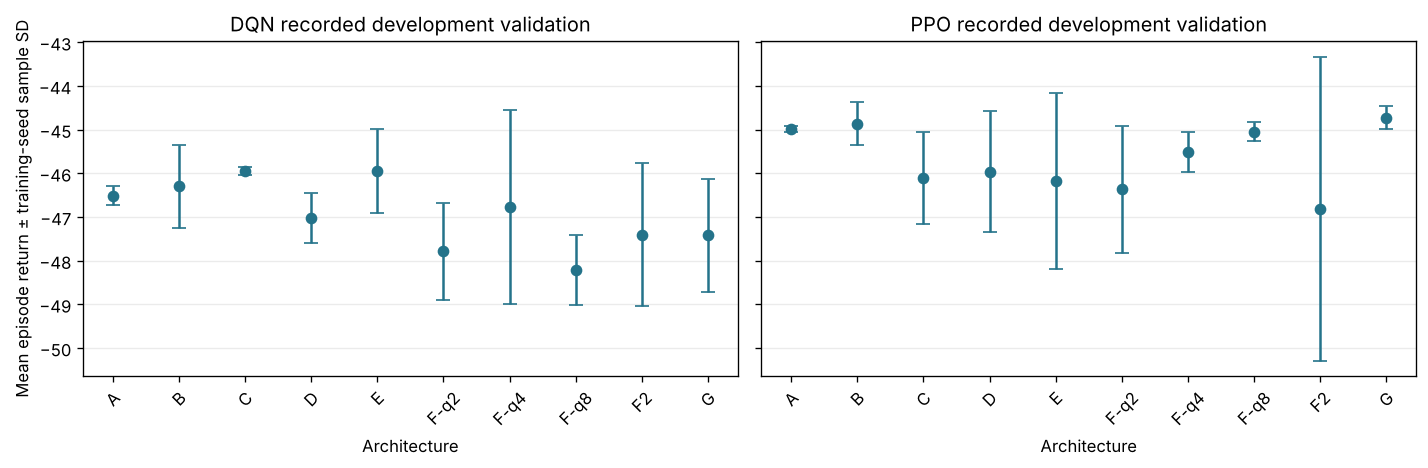

In [30]:
validation = pd.concat([recorded_table("validation_" + family)
                        for family in ("AE", "F", "F2", "G")], ignore_index=True)
validation["code"] = validation["code"].replace(
    {"F2-dual-structured": "F2", "G-cross-attention": "G"})
validation_view = validation[["algorithm", "code", "parameters",
                              "mean_validation_return", "std_validation_return"]]
display(validation_view)
validation_by_seed = pd.concat([recorded_table("validation_seeds_" + family)
                               for family in ("AE", "F", "F2", "G")], ignore_index=True)
display(validation_by_seed[["algorithm", "code", "training_seed",
                            "selected_checkpoint", "validation_return"]])
# Plot recorded means and training-seed spread separately for DQN and PPO.
fig, axes = plt.subplots(1, 2, figsize=(12, 4), sharey=True)
for ax, algorithm in zip(axes, ("DQN", "PPO")):
    group = validation[validation["algorithm"] == algorithm].set_index("code").loc[list(EXPECTED_COUNTS)]
    ax.errorbar(group.index, group["mean_validation_return"],
                yerr=group["std_validation_return"], fmt="o", capsize=4, color="#24738a")
    ax.set_title(algorithm + " recorded development validation")
    ax.set_xlabel("Architecture")
    ax.tick_params(axis="x", rotation=45)
    ax.grid(axis="y", alpha=.25)
axes[0].set_ylabel("Mean episode return ± training-seed sample SD")
fig.tight_layout()
plt.show()


## J. Frozen final held-out results

The completed evaluation used seeds 12000–12199 across four Dinner scenarios:
Off-Peak, Normal, Peak and Super-Peak. Each baseline and each trained model has
800 episodes. DQN A/C and PPO A/C/G each have three training seeds (31000–31002):
15 learned models plus three baselines, or 14,400 episodes in total.

Learned-architecture error bars show sample SD across three model means. Baseline
episode SD measures a different source of variation. These cells display saved
results and do not execute the final seeds.


In [31]:
RECORDED_CSV['final_overall'] = 'policy_group,policy_id,policy_name,algorithm,architecture_code,model_instances,episodes,mean_return,sample_sd_across_training_seeds_return,fixed_policy_episode_sd_return,mean_wait_ticks,sample_sd_across_training_seeds_wait_ticks,fixed_policy_episode_sd_wait_ticks,mean_lost_rate,sample_sd_across_training_seeds_lost_rate,fixed_policy_episode_sd_lost_rate,mean_served_rate,sample_sd_across_training_seeds_served_rate,fixed_policy_episode_sd_served_rate,mean_seat_utilisation,sample_sd_across_training_seeds_seat_utilisation,fixed_policy_episode_sd_seat_utilisation,mean_table_utilisation,sample_sd_across_training_seeds_table_utilisation,fixed_policy_episode_sd_table_utilisation,mean_drain_ticks,sample_sd_across_training_seeds_drain_ticks,fixed_policy_episode_sd_drain_ticks\r\nbaseline,Random-valid,Random-valid,Baseline,,1,800,-62.774125,,46.95832139162636,3.011433625,,1.3685801289360107,0.15950965858453614,,0.10583056667762838,0.8404903414154639,,0.10583056667762838,0.459665,,0.10495703084073801,0.560898875,,0.12183282565874588,3.0175,,3.3501825926739155\r\nbaseline,Compatible FIFO,Compatible FIFO,Baseline,,1,800,-45.739125,,42.49307541891469,2.076380875,,1.4515137051426712,0.11200149383557699,,0.09314262791960225,0.887998506164423,,0.09314262791960225,0.494771125,,0.1176731737632404,0.595884875,,0.13394025505291127,2.3925,,3.297656276986951\r\nbaseline,Best-fit Greedy,Best-fit Greedy,Baseline,,1,800,-42.80975,,39.21708338816571,1.92171325,,1.314109236548246,0.10804961942209995,,0.08848816816371949,0.8919503805779,,0.08848816816371949,0.501734125,,0.1229701811611371,0.595461375,,0.13378252202589427,2.32875,,3.1903599221782644\r\nlearned,DQN_A,DQN A Default,DQN,A,3,2400,-44.755916666666664,0.6580628571484153,,2.028162791666667,0.0333581487173518,,0.11264729391619906,0.0019086624802148971,,0.8873527060838009,0.0019086624802149277,,0.4968655,0.0012752466734420266,,0.5938980833333333,0.0014618521339240685,,2.3679166666666664,0.022718843133692743,\r\nlearned,DQN_C,DQN C Shallow-64,DQN,C,3,2400,-44.201708333333336,0.36077716316076863,,1.9996869166666666,0.016809948591874322,,0.11060528675070952,0.0017606992032591527,,0.8893947132492905,0.0017606992032591768,,0.498530125,0.0011925149959749078,,0.5945195,0.0008733631475508823,,2.3620833333333335,0.01282900359861737,\r\nlearned,PPO_A,PPO A Default,PPO,A,3,2400,-43.48104166666666,0.48609170516820627,,1.927112375,0.004560107555954639,,0.11147017811017658,0.002660365966947982,,0.8885298218898234,0.0026603659669479605,,0.4987767083333334,0.001800373356823065,,0.5942088333333333,0.0010793635952880884,,2.282083333333333,0.023859397170367298,\r\nlearned,PPO_C,PPO C Shallow-64,PPO,C,3,2400,-44.71225,1.1534407697732028,,2.0035120416666667,0.047115447778955134,,0.11351913511000898,0.0017576096191575523,,0.886480864889991,0.0017576096191575493,,0.49822141666666664,0.0005180983909532283,,0.5897555416666667,0.004920173690616356,,2.3745833333333333,0.08571695184345593,\r\nlearned,PPO_G,PPO G Cross-Attention,PPO,G,3,2400,-43.053625,0.2215009523117201,,1.9311675,0.01137005441183661,,0.10883410101015978,0.0008325330553402284,,0.8911658989898402,0.000832533055340187,,0.5010199166666667,0.0007077366469657501,,0.5950735,0.0005723905599544785,,2.285833333333333,0.04064582799419072,\r\n'


In [32]:
RECORDED_CSV['final_model_seeds'] = 'policy_group,policy_id,policy_name,algorithm,architecture_code,training_seed,selected_checkpoint,model_path,parameter_count,episodes,mean_return,sample_sd_episode_return,mean_wait_ticks,sample_sd_episode_wait_ticks,mean_lost_rate,sample_sd_episode_lost_rate,mean_served_rate,sample_sd_episode_served_rate,mean_seat_utilisation,sample_sd_episode_seat_utilisation,mean_table_utilisation,sample_sd_episode_table_utilisation,mean_drain_ticks,sample_sd_episode_drain_ticks\r\nbaseline,Random-valid,Random-valid,Baseline,,,,,,800,-62.774125,46.95832139162636,3.011433625,1.3685801289360107,0.15950965858453614,0.10583056667762838,0.8404903414154639,0.10583056667762838,0.459665,0.10495703084073801,0.560898875,0.12183282565874588,3.0175,3.3501825926739155\r\nbaseline,Compatible FIFO,Compatible FIFO,Baseline,,,,,,800,-45.739125,42.49307541891469,2.076380875,1.4515137051426712,0.11200149383557699,0.09314262791960225,0.887998506164423,0.09314262791960225,0.494771125,0.1176731737632404,0.595884875,0.13394025505291127,2.3925,3.297656276986951\r\nbaseline,Best-fit Greedy,Best-fit Greedy,Baseline,,,,,,800,-42.80975,39.21708338816571,1.92171325,1.314109236548246,0.10804961942209995,0.08848816816371949,0.8919503805779,0.08848816816371949,0.501734125,0.1229701811611371,0.595461375,0.13378252202589427,2.32875,3.1903599221782644\r\nlearned,DQN_A,DQN A Default,DQN,A,31000,51200,models/dqn_default_seed31000_best.zip,8268,800,-45.51525,40.44230975055641,2.06666125,1.3561645593505551,0.11484162001226268,0.09015282519253666,0.8851583799877373,0.09015282519253666,0.49541,0.12075504928328779,0.59221125,0.13358923938527728,2.38625,3.2654080218920263\r\nlearned,DQN_A,DQN A Default,DQN,A,31001,102400,models/dqn_default_seed31001_best.zip,8268,800,-44.351625,39.98139739342897,2.007833,1.3379987455019178,0.11172815390454374,0.08980654475510483,0.8882718460954563,0.08980654475510483,0.497786625,0.12168476881809105,0.594795875,0.13398871254455003,2.375,3.2384385674958085\r\nlearned,DQN_A,DQN A Default,DQN,A,31002,71680,models/dqn_default_seed31002_best.zip,8268,800,-44.400875,40.091991675145984,2.009994125,1.3436459766960003,0.11137210783179075,0.09031146316305073,0.8886278921682093,0.09031146316305072,0.497399875,0.12060148479663638,0.594687125,0.13360436381073398,2.3425,3.2505232081017374\r\nlearned,DQN_C,DQN C Shallow-64,DQN,C,31000,81920,models/dqn_mlp_64_seed31000_best.zip,4108,800,-44.1755,40.332222353224445,1.996554125,1.350528030553095,0.11114197891695052,0.08972555051097579,0.8888580210830495,0.08972555051097579,0.4985555,0.12194173907818341,0.594303,0.1340862270569127,2.35875,3.2129351265874595\r\nlearned,DQN_C,DQN C Shallow-64,DQN,C,31001,92160,models/dqn_mlp_64_seed31001_best.zip,4108,800,-43.85475,40.559742273640374,1.98466375,1.3743602117805922,0.10863869662641618,0.08988588922855256,0.8913613033735839,0.08988588922855256,0.49970975,0.12157149651910545,0.59548075,0.13384744638231366,2.37625,3.25583115088972\r\nlearned,DQN_C,DQN C Shallow-64,DQN,C,31002,102400,models/dqn_mlp_64_seed31002_best.zip,4108,800,-44.574875,40.15555742639686,2.017842875,1.3521171482724972,0.11203518470876186,0.0896487517003212,0.8879648152912382,0.0896487517003212,0.497325125,0.12096048157916785,0.59377475,0.1335776867048508,2.35125,3.2223210001930838\r\nlearned,PPO_A,PPO A Default,PPO,A,31000,40960,models/ppo_default_seed31000_best.zip,15821,800,-44.000625,40.36759083840645,1.93150025,1.3097155426573686,0.11449788043707536,0.0935574865425789,0.8855021195629247,0.0935574865425789,0.496810375,0.1186231236382118,0.59344125,0.13216367662944598,2.3,3.1559388361344674\r\nlearned,PPO_A,PPO A Default,PPO,A,31001,92160,models/ppo_default_seed31001_best.zip,15821,800,-43.405125,40.36541737532551,1.92743925,1.3205435188269383,0.11040611694535306,0.0932036752999528,0.8895938830546469,0.0932036752999528,0.4991755,0.12015966432590282,0.59374225,0.13112481672776463,2.255,3.149583280936455\r\nlearned,PPO_A,PPO A Default,PPO,A,31002,61440,models/ppo_default_seed31002_best.zip,15821,800,-43.037375,39.35709518989693,1.922397625,1.3106921010143595,0.10950653694810132,0.08957251721222273,0.8904934630518987,0.08957251721222273,0.50034425,0.12212494870339663,0.595443,0.1339219576448324,2.29125,3.1134450955418647\r\nlearned,PPO_C,PPO C Shallow-64,PPO,C,31000,81920,models/ppo_mlp_64_seed31000_best.zip,4173,800,-44.139125,39.53565089066526,1.985081,1.3049347570622971,0.11242389334332359,0.08990051999478683,0.8875761066566764,0.08990051999478683,0.498326375,0.12135537050042736,0.591237875,0.13191367138722943,2.37,3.219247496396296\r\nlearned,PPO_C,PPO C Shallow-64,PPO,C,31001,71680,models/ppo_mlp_64_seed31001_best.zip,4173,800,-46.04,42.68985042327335,2.057056875,1.422387944675848,0.1155464605847266,0.09391751231758014,0.8844535394152734,0.09391751231758014,0.497658875,0.11874481782770793,0.584264625,0.12402323659350406,2.4625,3.3098016910447297\r\nlearned,PPO_C,PPO C Shallow-64,PPO,C,31002,92160,models/ppo_mlp_64_seed31002_best.zip,4173,800,-43.957625,39.437396620144604,1.96839825,1.3071323523864202,0.11258705140197674,0.08918483414823516,0.8874129485980232,0.08918483414823516,0.498679,0.12164234834192274,0.593764125,0.1334601854556695,2.29125,3.206911097299468\r\nlearned,PPO_G,PPO G Cross-Attention,PPO,G,31000,81920,models/ppo_cross_attention_seed31000_best.zip,4097,800,-43.242875,39.50390040132775,1.944104375,1.3278963989620312,0.10894101102171294,0.08859081187076064,0.8910589889782871,0.08859081187076064,0.500792625,0.12236167305124285,0.594425875,0.13284611739383897,2.25,3.175311520790926\r\nlearned,PPO_G,PPO G Cross-Attention,PPO,G,31001,71680,models/ppo_cross_attention_seed31001_best.zip,4097,800,-43.108,39.35657932824607,1.926637125,1.3138777205051404,0.10960801471016461,0.08935928166339076,0.8903919852898354,0.08935928166339076,0.50045375,0.12225550395072324,0.595283,0.13378159834622283,2.2775,3.118115946982012\r\nlearned,PPO_G,PPO G Cross-Attention,PPO,G,31002,30720,models/ppo_cross_attention_seed31002_best.zip,4097,800,-42.81,39.23149612058945,1.922761,1.3145362648262806,0.10795327729860178,0.0885322810754652,0.8920467227013982,0.0885322810754652,0.501813375,0.1230635833239673,0.595511625,0.1338489698719385,2.33,3.1990455397597612\r\n'


In [33]:
RECORDED_CSV['final_scenarios'] = 'policy_group,policy_id,policy_name,algorithm,architecture_code,scenario,model_instances,episodes,mean_return,sample_sd_across_training_seeds_return,fixed_policy_episode_sd_return,mean_wait_ticks,sample_sd_across_training_seeds_wait_ticks,fixed_policy_episode_sd_wait_ticks,mean_lost_rate,sample_sd_across_training_seeds_lost_rate,fixed_policy_episode_sd_lost_rate,mean_served_rate,sample_sd_across_training_seeds_served_rate,fixed_policy_episode_sd_served_rate,mean_seat_utilisation,sample_sd_across_training_seeds_seat_utilisation,fixed_policy_episode_sd_seat_utilisation,mean_table_utilisation,sample_sd_across_training_seeds_table_utilisation,fixed_policy_episode_sd_table_utilisation,mean_drain_ticks,sample_sd_across_training_seeds_drain_ticks,fixed_policy_episode_sd_drain_ticks\r\nbaseline,Random-valid,Random-valid,Baseline,,off_peak,1,200,-22.0985,,18.486060149454406,1.7854645,,0.9708243466508244,0.07690017447521964,,0.07414654498278,0.9230998255247803,,0.07414654498278,0.346015,,0.08813208665686104,0.421255,,0.09030316875078172,1.41,,2.647061516732627\r\nbaseline,Random-valid,Random-valid,Baseline,,normal,1,200,-47.7935,,30.356788049022352,2.69962,,1.1177408789439132,0.13589382318618787,,0.08966728653246384,0.8641061768138122,,0.08966728653246384,0.450177,,0.07169831317093721,0.5405905,,0.08177999939628443,2.325,,2.9636618324779285\r\nbaseline,Random-valid,Random-valid,Baseline,,peak,1,200,-72.62650000000001,,36.886618997344776,3.3869445,,1.0932160394056698,0.18495619167227298,,0.0901206878090224,0.815043808327727,,0.09012068780902241,0.496253,,0.07426008004602615,0.6062615,,0.07349301725795718,3.66,,3.569046154403345\r\nbaseline,Random-valid,Random-valid,Baseline,,super_peak,1,200,-108.578,,46.20848881094203,4.1737055,,1.012751758994514,0.24028844500446406,,0.09317562968157612,0.7597115549955359,,0.09317562968157612,0.546215,,0.062143815816387594,0.6754885,,0.06383636994998979,4.675,,3.2063653713312776\r\nbaseline,Compatible FIFO,Compatible FIFO,Baseline,,off_peak,1,200,-11.788,,15.116697014996896,0.802879,,0.876366148415973,0.04709183278363038,,0.06224561937861548,0.9529081672163696,,0.06224561937861548,0.3654195,,0.0956869948040125,0.439734,,0.09654941372402145,0.655,,2.354504930412481\r\nbaseline,Compatible FIFO,Compatible FIFO,Baseline,,normal,1,200,-30.328500000000002,,26.415446557538466,1.631821,,1.1029296525396606,0.08559027695436969,,0.07798053870607238,0.9144097230456303,,0.07798053870607238,0.483278,,0.08066906100243808,0.573637,,0.09000965738805797,1.53,,2.5986273918374754\r\nbaseline,Compatible FIFO,Compatible FIFO,Baseline,,peak,1,200,-53.017,,34.31233147801657,2.456813,,1.1976754551674476,0.1297901454205369,,0.08273790846157704,0.8702098545794631,,0.08273790846157704,0.5369675,,0.082977917954661,0.647779,,0.08037361162863814,2.89,,3.403796284404906\r\nbaseline,Compatible FIFO,Compatible FIFO,Baseline,,super_peak,1,200,-87.823,,43.77102333070459,3.4140105,,1.1261211545448013,0.18553372018377096,,0.08569866604659315,0.814466279816229,,0.08569866604659315,0.5934195,,0.06729973881056188,0.7223895,,0.06598123488184095,4.495,,3.3625150613325796\r\nbaseline,Best-fit Greedy,Best-fit Greedy,Baseline,,off_peak,1,200,-11.6,,14.46015839832063,0.7885305,,0.8332071080133497,0.04735291791085994,,0.06097191644507081,0.9526470820891401,,0.06097191644507081,0.3660035,,0.09663413016795144,0.4395975,,0.09673820416191507,0.665,,2.3687188827990213\r\nbaseline,Best-fit Greedy,Best-fit Greedy,Baseline,,normal,1,200,-29.402,,25.657302701366483,1.570957,,1.070711130405804,0.08411142203431206,,0.0763847516345507,0.9158885779656879,,0.0763847516345507,0.4867345,,0.08347787815015581,0.573297,,0.09084637035143535,1.585,,2.6491251993078846\r\nbaseline,Best-fit Greedy,Best-fit Greedy,Baseline,,peak,1,200,-49.396,,31.76575198220522,2.250921,,1.0796204133135017,0.1242126616447198,,0.0781396874596247,0.8757873383552802,,0.0781396874596247,0.546158,,0.08533898492329689,0.647693,,0.07945468763980951,2.925,,3.3218289749313508\r\nbaseline,Best-fit Greedy,Best-fit Greedy,Baseline,,super_peak,1,200,-80.841,,40.51903974564979,3.0764445,,1.0315511905686348,0.17652147609850802,,0.08079368430124954,0.823478523901492,,0.08079368430124954,0.6080405,,0.0710101543432293,0.721258,,0.06618881804482427,4.14,,3.195537088883833\r\nlearned,DQN_A,DQN A Default,DQN,A,off_peak,3,600,-12.671000000000001,0.4614496180516351,,0.8587643333333334,0.027477772163756874,,0.05147710758411783,0.0020513802478522585,,0.9485228924158822,0.002051380247852247,,0.3631545,0.001463966273518629,,0.4381278333333333,0.0014678275046248813,,0.7083333333333334,0.02886751345948125,\r\nlearned,DQN_A,DQN A Default,DQN,A,normal,3,600,-31.173333333333332,1.2392857149718681,,1.6624943333333333,0.056582857345077,,0.09097336888548985,0.004868150548016482,,0.9090266311145101,0.0048681505480164715,,0.480854,0.003435803654168825,,0.5706833333333333,0.0028894160453858675,,1.5933333333333333,0.01892969448600089,\r\nlearned,DQN_A,DQN A Default,DQN,A,peak,3,600,-51.839333333333336,0.3128547319976667,,2.383722666666667,0.02250419267788415,,0.12851147774980973,0.00026373134078812706,,0.8714885222501902,0.0002637313407881488,,0.5401793333333333,0.00024234599921049322,,0.6459866666666667,0.0006198270592135693,,3.021666666666667,0.09169696468985936,\r\nlearned,DQN_A,DQN A Default,DQN,A,super_peak,3,600,-83.34,0.7909900441851365,,3.2076698333333336,0.04202704226546692,,0.17962722144537882,0.0009729465338977616,,0.8203727785546212,0.0009729465338977722,,0.6032741666666667,0.0005221025601673653,,0.7207945,0.0010164985243472269,,4.148333333333333,0.09827681991870353,\r\nlearned,DQN_C,DQN C Shallow-64,DQN,C,off_peak,3,600,-12.42,0.693780945255777,,0.8491581666666667,0.05297597757789217,,0.049733493957071634,0.0026438691093796964,,0.9502665060429284,0.0026438691093796695,,0.3634585,0.001707347284532344,,0.438066,0.0012031948096629889,,0.6566666666666666,0.08098353742170895,\r\nlearned,DQN_C,DQN C Shallow-64,DQN,C,normal,3,600,-30.7275,0.875998430363891,,1.647875,0.03929731241128329,,0.08779457976204574,0.004136737443711429,,0.9122054202379543,0.0041367374437114406,,0.48282183333333334,0.002728288352306866,,0.5716068333333333,0.00171075892028461,,1.6566666666666667,0.03253203549323853,\r\nlearned,DQN_C,DQN C Shallow-64,DQN,C,peak,3,600,-50.757666666666665,0.5550111109998901,,2.3281316666666667,0.03647347014040935,,0.12569258774402542,0.00126936338026413,,0.8743074122559745,0.0012693633802641254,,0.5435558333333333,0.00099257422056658,,0.6477128333333333,0.0008818906300291988,,2.9966666666666666,0.12829003598617209,\r\nlearned,DQN_C,DQN C Shallow-64,DQN,C,super_peak,3,600,-82.90166666666667,0.15164624404624594,,3.173582833333333,0.011209106480149668,,0.17920048553969525,0.0005806175831285481,,0.8207995144603047,0.0005806175831285235,,0.6042843333333333,0.0006767079010424886,,0.7206923333333334,0.0003548324722081534,,4.138333333333333,0.00763762615825957,\r\nlearned,PPO_A,PPO A Default,PPO,A,off_peak,3,600,-11.651833333333334,0.09879819499025909,,0.7910101666666667,0.007885471091401766,,0.04728576479942071,0.0006278181624469982,,0.9527142352005793,0.000627818162447041,,0.365564,0.00017266803410014223,,0.4396583333333333,0.00035716044480503805,,0.66,0.017320508075688787,\r\nlearned,PPO_A,PPO A Default,PPO,A,normal,3,600,-29.661666666666665,0.32175003237503086,,1.5749771666666665,0.0026984194602273077,,0.08574189143339513,0.0025497172215537753,,0.9142581085666048,0.002549717221553795,,0.4851535,0.001079899416612485,,0.5734061666666667,0.001294068616161239,,1.535,0.06244997998398391,\r\nlearned,PPO_A,PPO A Default,PPO,A,peak,3,600,-50.31216666666667,0.571190058853733,,2.2638635000000003,0.012808679976874987,,0.1288868421951663,0.003199767513004862,,0.8711131578048337,0.003199767513004839,,0.5429248333333333,0.0024844571003205386,,0.6468641666666667,0.0007867767048745901,,2.81,0.09500000000000001,\r\nlearned,PPO_A,PPO A Default,PPO,A,super_peak,3,600,-82.2985,1.1291172436908388,,3.0785986666666667,0.00548665235670477,,0.1839662140127242,0.005571290960953218,,0.8160337859872758,0.005571290960953203,,0.6014645000000001,0.003969489765700372,,0.7169066666666667,0.004571320414643198,,4.123333333333333,0.12513326229797309,\r\nlearned,PPO_C,PPO C Shallow-64,PPO,C,off_peak,3,600,-12.076500000000001,0.267767156313092,,0.827319,0.018938814449431636,,0.04956691797187132,0.0014856558333796988,,0.9504330820281287,0.001485655833379714,,0.36460716666666665,0.0011070598824514278,,0.438118,0.0008323321152040001,,0.6966666666666667,0.037527767497325656,\r\nlearned,PPO_C,PPO C Shallow-64,PPO,C,normal,3,600,-30.017,0.34445173827402903,,1.6047911666666668,0.024820669382257507,,0.08624303071032574,0.0018629811411467402,,0.9137569692896743,0.001862981141146708,,0.4854016666666667,0.0014760699791450717,,0.5714741666666666,0.0008707858998246256,,1.645,0.11302654555457319,\r\nlearned,PPO_C,PPO C Shallow-64,PPO,C,peak,3,600,-50.905166666666666,0.16683100231471934,,2.3253150000000002,0.011165324480282672,,0.12840453042246408,0.0013204288817691644,,0.8715954695775359,0.0013204288817691278,,0.543377,0.0012713843832610273,,0.644589,0.0011999146844671948,,2.9833333333333334,0.12291596044994853,\r\nlearned,PPO_C,PPO C Shallow-64,PPO,C,super_peak,3,600,-85.85033333333334,5.274958585935375,,3.256623,0.22223065257295183,,0.18986206133537478,0.010734686454519663,,0.8101379386646252,0.01073468645451965,,0.5994998333333333,0.0058221901448967635,,0.7048409999999999,0.02026658654657959,,4.173333333333334,0.1578237413488015,\r\nlearned,PPO_G,PPO G Cross-Attention,PPO,G,off_peak,3,600,-11.651833333333334,0.0558621816019869,,0.7916843333333333,0.0033142217915120235,,0.04751286498410378,0.00016644930572870049,,0.9524871350158962,0.00016644930572872664,,0.36578133333333335,0.00028060039795646107,,0.4395073333333333,8.651637609915418e-05,,0.6666666666666667,0.0028867513459481316,\r\nlearned,PPO_G,PPO G Cross-Attention,PPO,G,normal,3,600,-29.451,0.17861410918513743,,1.5708638333333333,0.0019559148967512653,,0.0845267482475696,0.0011990568186007373,,0.9154732517524304,0.001199056818600712,,0.4863831666666667,0.0006289885399062081,,0.573295,0.0002465060851175714,,1.5733333333333333,0.01607275126832163,\r\nlearned,PPO_G,PPO G Cross-Attention,PPO,G,peak,3,600,-49.864333333333335,0.42634913314481165,,2.269988666666667,0.02381383244216146,,0.12581532300369164,0.001404754313062142,,0.8741846769963083,0.0014047543130621615,,0.5450275,0.0010039510695248417,,0.64715,0.0006436590712481116,,2.8666666666666667,0.052041649986653137,\r\nlearned,PPO_G,PPO G Cross-Attention,PPO,G,super_peak,3,600,-81.24733333333333,0.4916193480054803,,3.0921331666666667,0.02377430803584696,,0.17748146780527407,0.0011711556246179514,,0.8225185321947259,0.0011711556246179289,,0.6068876666666667,0.0012811733229088468,,0.7203416666666667,0.0018344611152415215,,4.036666666666667,0.10750968948580063,\r\n'


In [34]:
RECORDED_CSV['paired_architectures'] = 'policy_id,policy_name,algorithm,architecture_code,training_seed_models,paired_episodes,mean_paired_delta_return,sample_sd_model_mean_delta_return,better_count,better_percent,same_count,same_percent,worse_count,worse_percent\r\nDQN_A,DQN A Default,DQN,A,3,2400,-1.9461666666666666,0.6580628571484137,788,32.833333333333336,453,18.875,1159,48.291666666666664\r\nDQN_C,DQN C Shallow-64,DQN,C,3,2400,-1.3919583333333334,0.36077716316077063,669,27.875,663,27.625,1068,44.5\r\nPPO_A,PPO A Default,PPO,A,3,2400,-0.6712916666666667,0.4860917051682052,272,11.333333333333334,1506,62.75,622,25.916666666666668\r\nPPO_C,PPO C Shallow-64,PPO,C,3,2400,-1.9025,1.1534407697732032,446,18.583333333333332,793,33.041666666666664,1161,48.375\r\nPPO_G,PPO G Cross-Attention,PPO,G,3,2400,-0.243875,0.22150095231172262,184,7.666666666666667,1863,77.625,353,14.708333333333334\r\n'


In [35]:
RECORDED_CSV['paired_models'] = 'policy_id,policy_name,algorithm,architecture_code,training_seed,paired_episodes,mean_paired_delta_return,better_count,better_percent,same_count,same_percent,worse_count,worse_percent\r\nDQN_A,DQN A Default,DQN,A,31000,800,-2.7055000000000002,252,31.5,123,15.375,425,53.125\r\nDQN_A,DQN A Default,DQN,A,31001,800,-1.5418749999999999,266,33.25,174,21.75,360,45.0\r\nDQN_A,DQN A Default,DQN,A,31002,800,-1.5911250000000001,270,33.75,156,19.5,374,46.75\r\nDQN_C,DQN C Shallow-64,DQN,C,31000,800,-1.36575,215,26.875,248,31.0,337,42.125\r\nDQN_C,DQN C Shallow-64,DQN,C,31001,800,-1.0450000000000002,197,24.625,275,34.375,328,41.0\r\nDQN_C,DQN C Shallow-64,DQN,C,31002,800,-1.765125,257,32.125,140,17.5,403,50.375\r\nPPO_A,PPO A Default,PPO,A,31000,800,-1.1908750000000001,85,10.625,465,58.125,250,31.25\r\nPPO_A,PPO A Default,PPO,A,31001,800,-0.595375,104,13.0,474,59.25,222,27.75\r\nPPO_A,PPO A Default,PPO,A,31002,800,-0.22762500000000013,83,10.375,567,70.875,150,18.75\r\nPPO_C,PPO C Shallow-64,PPO,C,31000,800,-1.3293750000000002,195,24.375,187,23.375,418,52.25\r\nPPO_C,PPO C Shallow-64,PPO,C,31001,800,-3.23025,84,10.5,341,42.625,375,46.875\r\nPPO_C,PPO C Shallow-64,PPO,C,31002,800,-1.147875,167,20.875,265,33.125,368,46.0\r\nPPO_G,PPO G Cross-Attention,PPO,G,31000,800,-0.43312500000000004,125,15.625,463,57.875,212,26.5\r\nPPO_G,PPO G Cross-Attention,PPO,G,31001,800,-0.29825,56,7.0,613,76.625,131,16.375\r\nPPO_G,PPO G Cross-Attention,PPO,G,31002,800,-0.0002499999999999769,3,0.375,787,98.375,10,1.25\r\n'


In [36]:
RECORDED_CSV['preregistered'] = 'comparison_id,research_question,scope,training_seed,challenger,reference,episodes_per_model,challenger_mean_return,reference_mean_return,delta_return,sample_sd_delta_return,challenger_mean_wait_ticks,reference_mean_wait_ticks,delta_wait_ticks,sample_sd_delta_wait_ticks,challenger_mean_lost_rate,reference_mean_lost_rate,delta_lost_rate,sample_sd_delta_lost_rate,challenger_mean_served_rate,reference_mean_served_rate,delta_served_rate,sample_sd_delta_served_rate,challenger_mean_seat_utilisation,reference_mean_seat_utilisation,delta_seat_utilisation,sample_sd_delta_seat_utilisation,challenger_mean_table_utilisation,reference_mean_table_utilisation,delta_table_utilisation,sample_sd_delta_table_utilisation,challenger_mean_drain_ticks,reference_mean_drain_ticks,delta_drain_ticks,sample_sd_delta_drain_ticks\r\nDQN_C_vs_A,Does the smaller plain DQN retain or improve final held-out performance relative to the default DQN?,training_seed,31000,DQN C Shallow-64,DQN A Default,800,-44.1755,-45.51525,1.3397500000000022,,1.996554125,2.06666125,-0.07010712500000005,,0.11114197891695052,0.11484162001226268,-0.0036996410953121645,,0.8888580210830495,0.8851583799877373,0.0036996410953121783,,0.4985555,0.49541,0.0031454999999999678,,0.594303,0.59221125,0.002091750000000059,,2.35875,2.38625,-0.027499999999999858,\r\nDQN_C_vs_A,Does the smaller plain DQN retain or improve final held-out performance relative to the default DQN?,training_seed,31001,DQN C Shallow-64,DQN A Default,800,-43.85475,-44.351625,0.49687499999999574,,1.98466375,2.007833,-0.023169250000000252,,0.10863869662641618,0.11172815390454374,-0.0030894572781275664,,0.8913613033735839,0.8882718460954563,0.003089457278127594,,0.49970975,0.497786625,0.0019231250000000255,,0.59548075,0.594795875,0.0006848750000000292,,2.37625,2.375,0.0012500000000001954,\r\nDQN_C_vs_A,Does the smaller plain DQN retain or improve final held-out performance relative to the default DQN?,training_seed,31002,DQN C Shallow-64,DQN A Default,800,-44.574875,-44.400875,-0.1739999999999995,,2.017842875,2.009994125,0.00784874999999996,,0.11203518470876186,0.11137210783179075,0.0006630768769711193,,0.8879648152912382,0.8886278921682093,-0.0006630768769710915,,0.497325125,0.497399875,-7.47500000000123e-05,,0.59377475,0.594687125,-0.0009123749999999653,,2.35125,2.3425,0.008750000000000036,\r\nDQN_C_vs_A,Does the smaller plain DQN retain or improve final held-out performance relative to the default DQN?,aggregate_across_training_seeds,,DQN C Shallow-64,DQN A Default,800,-44.201708333333336,-44.755916666666664,0.5542083333333329,0.7585018780189902,1.9996869166666666,2.028162791666667,-0.028475875000000112,0.039247927504797935,0.11060528675070952,0.11264729391619906,-0.002042007165489537,0.002362454408082822,0.8893947132492905,0.8873527060838009,0.00204200716548956,0.002362454408082817,0.498530125,0.4968655,0.0016646249999999936,0.001625613485157213,0.5945195,0.5938980833333333,0.0006214166666667076,0.0015030675214235615,2.3620833333333335,2.3679166666666664,-0.005833333333333209,0.019134937505341693\r\nPPO_G_vs_A,Can the compact cross-attention design match or improve on the much larger default PPO?,training_seed,31000,PPO G Cross-Attention,PPO A Default,800,-43.242875,-44.000625,0.7577500000000015,,1.944104375,1.93150025,0.012604124999999966,,0.10894101102171294,0.11449788043707536,-0.005556869415362417,,0.8910589889782871,0.8855021195629247,0.0055568694153623754,,0.500792625,0.496810375,0.003982249999999965,,0.594425875,0.59344125,0.0009846249999999612,,2.25,2.3,-0.04999999999999982,\r\nPPO_G_vs_A,Can the compact cross-attention design match or improve on the much larger default PPO?,training_seed,31001,PPO G Cross-Attention,PPO A Default,800,-43.108,-43.405125,0.2971250000000012,,1.926637125,1.92743925,-0.0008021249999998759,,0.10960801471016461,0.11040611694535306,-0.000798102235188447,,0.8903919852898354,0.8895938830546469,0.0007981022351885025,,0.50045375,0.4991755,0.0012782500000000363,,0.595283,0.59374225,0.0015407499999999796,,2.2775,2.255,0.022499999999999964,\r\nPPO_G_vs_A,Can the compact cross-attention design match or improve on the much larger default PPO?,training_seed,31002,PPO G Cross-Attention,PPO A Default,800,-42.81,-43.037375,0.227374999999995,,1.922761,1.922397625,0.0003633749999998326,,0.10795327729860178,0.10950653694810132,-0.0015532596494995388,,0.8920467227013982,0.8904934630518987,0.0015532596494994833,,0.501813375,0.50034425,0.00146912499999996,,0.595511625,0.595443,6.862500000004434e-05,,2.33,2.29125,0.038750000000000284,\r\nPPO_G_vs_A,Can the compact cross-attention design match or improve on the much larger default PPO?,aggregate_across_training_seeds,,PPO G Cross-Attention,PPO A Default,800,-43.053625,-43.48104166666666,0.4274166666666659,0.28819498426991175,1.9311675,1.927112375,0.0040551249999999745,0.0074265502295816814,0.10883410101015978,0.11147017811017658,-0.002636077100016801,0.002557505912433783,0.8911658989898402,0.8885298218898234,0.002636077100016787,0.0025575059124337512,0.5010199166666667,0.4987767083333334,0.0022432083333333206,0.0015090751323934366,0.5950735,0.5942088333333333,0.0008646666666666617,0.0007433575890567604,2.285833333333333,2.282083333333333,0.003750000000000142,0.04725264542858949\r\nPPO_G_vs_C,"At a similar parameter budget, does cross-attention retain the validation advantage over the plain MLP on fresh held-out episodes?",training_seed,31000,PPO G Cross-Attention,PPO C Shallow-64,800,-43.242875,-44.139125,0.896250000000002,,1.944104375,1.985081,-0.0409766250000001,,0.10894101102171294,0.11242389334332359,-0.0034828823216106475,,0.8910589889782871,0.8875761066566764,0.0034828823216106475,,0.500792625,0.498326375,0.002466250000000003,,0.594425875,0.591237875,0.0031879999999999686,,2.25,2.37,-0.1200000000000001,\r\nPPO_G_vs_C,"At a similar parameter budget, does cross-attention retain the validation advantage over the plain MLP on fresh held-out episodes?",training_seed,31001,PPO G Cross-Attention,PPO C Shallow-64,800,-43.108,-46.04,2.932000000000002,,1.926637125,2.057056875,-0.13041974999999972,,0.10960801471016461,0.1155464605847266,-0.005938445874561993,,0.8903919852898354,0.8844535394152734,0.005938445874562048,,0.50045375,0.497658875,0.00279487500000003,,0.595283,0.584264625,0.011018375000000025,,2.2775,2.4625,-0.18500000000000005,\r\nPPO_G_vs_C,"At a similar parameter budget, does cross-attention retain the validation advantage over the plain MLP on fresh held-out episodes?",training_seed,31002,PPO G Cross-Attention,PPO C Shallow-64,800,-42.81,-43.957625,1.147624999999998,,1.922761,1.96839825,-0.04563724999999996,,0.10795327729860178,0.11258705140197674,-0.004633774103374955,,0.8920467227013982,0.8874129485980232,0.004633774103374955,,0.501813375,0.498679,0.0031343750000000226,,0.595511625,0.593764125,0.001747500000000013,,2.33,2.29125,0.038750000000000284,\r\nPPO_G_vs_C,"At a similar parameter budget, does cross-attention retain the validation advantage over the plain MLP on fresh held-out episodes?",aggregate_across_training_seeds,,PPO G Cross-Attention,PPO C Shallow-64,800,-43.053625,-44.71225,1.6586250000000007,1.109914530774781,1.9311675,2.0035120416666667,-0.0723445416666666,0.05034856227905311,0.10883410101015978,0.11351913511000898,-0.004685034099849199,0.001228584055355865,0.8911658989898402,0.886480864889991,0.004685034099849217,0.0012285840553558933,0.5010199166666667,0.49822141666666664,0.0027985000000000184,0.00033407725060980494,0.5950735,0.5897555416666667,0.005317958333333335,0.004988970103408969,2.285833333333333,2.3745833333333333,-0.08874999999999995,0.11510185706581821\r\n'


In [37]:
RECORDED_CSV['roster'] = 'policy_group,algorithm,architecture_code,architecture_name,research_role,training_seed,selected_checkpoint,model_path,exists,load_verified,model_class,extractor_class,parameter_count,gamma,action_masking_verified,dqn_target_hook_present,model_bytes,model_sha256,notes\r\nbaseline,Baseline,,Random-valid,weak valid-action reference,,,,True,not applicable,,,,,valid-action policy by construction,,,,Fixed baseline; 800 episodes.\r\nbaseline,Baseline,,Compatible FIFO,traditional queue-order reference,,,,True,not applicable,,,,,valid-action policy by construction,,,,Fixed baseline; 800 episodes.\r\nbaseline,Baseline,,Best-fit Greedy,strong heuristic reference,,,,True,not applicable,,,,,valid-action policy by construction,,,,Fixed baseline and paired learned-agent comparator; 800 episodes.\r\nlearned,DQN,A,A Default,default DQN reference,31000,51200,models/dqn_default_seed31000_best.zip,True,True,MaskedDQN,FlattenExtractor,8268,1.0,True,True,160011,abb3312fc04d73c83e910b2a8e5f2dd511a83239afbaeaac3486843526cefd0b,800 episodes for this trained seed; architecture aggregate uses all three trained seeds.\r\nlearned,DQN,A,A Default,default DQN reference,31001,102400,models/dqn_default_seed31001_best.zip,True,True,MaskedDQN,FlattenExtractor,8268,1.0,True,True,160018,84cf1a5de4b8c962897c2cbc09af26413aa397c5b05bd18268fc593d68ea8ebd,800 episodes for this trained seed; architecture aggregate uses all three trained seeds.\r\nlearned,DQN,A,A Default,default DQN reference,31002,71680,models/dqn_default_seed31002_best.zip,True,True,MaskedDQN,FlattenExtractor,8268,1.0,True,True,160027,ad622438f4b11fb5301568da2677de18384f09346ee8f441056d3e10b5dc814e,800 episodes for this trained seed; architecture aggregate uses all three trained seeds.\r\nlearned,DQN,C,C Shallow-64,smaller plain DQN selected from validation,31000,81920,models/dqn_mlp_64_seed31000_best.zip,True,True,MaskedDQN,SimpleRestaurantExtractor,4108,1.0,True,True,91608,c1b6f7c705e2b7e69a9f660f7ff31114cd0e0fdca7d78f3c16467bc0975ca5d7,800 episodes for this trained seed; architecture aggregate uses all three trained seeds.\r\nlearned,DQN,C,C Shallow-64,smaller plain DQN selected from validation,31001,92160,models/dqn_mlp_64_seed31001_best.zip,True,True,MaskedDQN,SimpleRestaurantExtractor,4108,1.0,True,True,91612,f9f52149a15b2c709da9b15e743e04aab57cb7438929641161a834ac1e80ff9f,800 episodes for this trained seed; architecture aggregate uses all three trained seeds.\r\nlearned,DQN,C,C Shallow-64,smaller plain DQN selected from validation,31002,102400,models/dqn_mlp_64_seed31002_best.zip,True,True,MaskedDQN,SimpleRestaurantExtractor,4108,1.0,True,True,91595,9a10adc6c8a8cdacf2ec53699dff337222d4edc42aa4768fc1236f1e1af356c9,800 episodes for this trained seed; architecture aggregate uses all three trained seeds.\r\nlearned,PPO,A,A Default,default PPO reference,31000,40960,models/ppo_default_seed31000_best.zip,True,True,MaskablePPO,FlattenExtractor,15821,1.0,True,not applicable,221225,66a782f50654909849e72a48face7064a8f9acabf58f555a55431d1aa9680ea2,800 episodes for this trained seed; architecture aggregate uses all three trained seeds.\r\nlearned,PPO,A,A Default,default PPO reference,31001,92160,models/ppo_default_seed31001_best.zip,True,True,MaskablePPO,FlattenExtractor,15821,1.0,True,not applicable,221245,e307376fdb4348ac2316763bf1b305e41c63c4b78e79529867b3a77447aafb54,800 episodes for this trained seed; architecture aggregate uses all three trained seeds.\r\nlearned,PPO,A,A Default,default PPO reference,31002,61440,models/ppo_default_seed31002_best.zip,True,True,MaskablePPO,FlattenExtractor,15821,1.0,True,not applicable,221225,1d2b50d1cda12831046a9c34872549c590f570e5ee3dba226a64c0d9ce4bc90e,800 episodes for this trained seed; architecture aggregate uses all three trained seeds.\r\nlearned,PPO,C,C Shallow-64,similarly sized plain PPO comparator for G,31000,81920,models/ppo_mlp_64_seed31000_best.zip,True,True,MaskablePPO,SimpleRestaurantExtractor,4173,1.0,True,not applicable,76578,9f6f856f648926a3905547b3e03b485ff2e8f30edfc8071d476545c14367cd1e,800 episodes for this trained seed; architecture aggregate uses all three trained seeds.\r\nlearned,PPO,C,C Shallow-64,similarly sized plain PPO comparator for G,31001,71680,models/ppo_mlp_64_seed31001_best.zip,True,True,MaskablePPO,SimpleRestaurantExtractor,4173,1.0,True,not applicable,76582,e2f1e9c8f0988d22d4b917dd495f68c8f26c3b785b9238261f61b9ddf96c36be,800 episodes for this trained seed; architecture aggregate uses all three trained seeds.\r\nlearned,PPO,C,C Shallow-64,similarly sized plain PPO comparator for G,31002,92160,models/ppo_mlp_64_seed31002_best.zip,True,True,MaskablePPO,SimpleRestaurantExtractor,4173,1.0,True,not applicable,76578,6893ea4bcd0a64f7aaf0c33778bdc8754a38464d73e46d9b78702596ab16f300,800 episodes for this trained seed; architecture aggregate uses all three trained seeds.\r\nlearned,PPO,G,G Cross-Attention,restaurant-specific party-to-table cross-attention design selected from validation,31000,81920,models/ppo_cross_attention_seed31000_best.zip,True,True,MaskablePPO,CrossAttentionRestaurantExtractor,4097,1.0,True,not applicable,90306,ab3650519430ea98f69fd8a65a2eb8bcbffe39ea3f28ed4025e51622a88c72f3,800 episodes for this trained seed; architecture aggregate uses all three trained seeds.\r\nlearned,PPO,G,G Cross-Attention,restaurant-specific party-to-table cross-attention design selected from validation,31001,71680,models/ppo_cross_attention_seed31001_best.zip,True,True,MaskablePPO,CrossAttentionRestaurantExtractor,4097,1.0,True,not applicable,90310,be72014fcbe437bbd36d1c4981b24a0fd74ca3cbbf3f6b4a771cd3907c879c57,800 episodes for this trained seed; architecture aggregate uses all three trained seeds.\r\nlearned,PPO,G,G Cross-Attention,restaurant-specific party-to-table cross-attention design selected from validation,31002,30720,models/ppo_cross_attention_seed31002_best.zip,True,True,MaskablePPO,CrossAttentionRestaurantExtractor,4097,1.0,True,not applicable,90290,a2b76f0be20c7ab0ff1fd74ec85b5708cdf342975037bacb433b171fdd7447cf,800 episodes for this trained seed; architecture aggregate uses all three trained seeds.\r\n'


### Frozen model/checkpoint roster

The table links report codes A, C and G to selected checkpoints and current submission filenames. Displaying it does not load a model.


In [38]:
roster = recorded_table("roster")
display(roster[roster["policy_group"] == "learned"][
    ["algorithm", "architecture_code", "training_seed", "selected_checkpoint",
     "parameter_count", "model_path"]])
print("Paths above are recorded provenance only; no model file is opened.")


,algorithm,architecture_code,training_seed,selected_checkpoint,parameter_count,model_path
3,DQN,A,31000.0000,51200.0000,8268.0000,models/dqn_default_seed31000_best.zip
4,DQN,A,31001.0000,102400.0000,8268.0000,models/dqn_default_seed31001_best.zip
5,DQN,A,31002.0000,71680.0000,8268.0000,models/dqn_default_seed31002_best.zip
6,DQN,C,31000.0000,81920.0000,4108.0000,models/architecture_study/dqn/shallow_64/seed_...
7,DQN,C,31001.0000,92160.0000,4108.0000,models/architecture_study/dqn/shallow_64/seed_...
8,DQN,C,31002.0000,102400.0000,4108.0000,models/architecture_study/dqn/shallow_64/seed_...
9,PPO,A,31000.0000,40960.0000,15821.0000,models/ppo_default_seed31000_best.zip
10,PPO,A,31001.0000,92160.0000,15821.0000,models/ppo_default_seed31001_best.zip
11,PPO,A,31002.0000,61440.0000,15821.0000,models/ppo_default_seed31002_best.zip
12,PPO,C,31000.0000,81920.0000,4173.0000,models/architecture_study/ppo/shallow_64/seed_...


Paths above are recorded provenance only; no model file is opened.


### Overall and per-training-seed results

Learned-policy means combine three training seeds; their sample SD describes variation between trained models. The baseline episode SD is a different measure.


,policy_name,episodes,mean_return,sample_sd_across_training_seeds_return,fixed_policy_episode_sd_return,mean_wait_ticks,mean_lost_rate,mean_served_rate,mean_seat_utilisation,mean_table_utilisation,mean_drain_ticks
0,Random-valid,800,-62.7741,NaN,46.9583,3.0114,0.1595,0.8405,0.4597,0.5609,3.0175
1,Compatible FIFO,800,-45.7391,NaN,42.4931,2.0764,0.1120,0.8880,0.4948,0.5959,2.3925
2,Best-fit Greedy,800,-42.8098,NaN,39.2171,1.9217,0.1080,0.8920,0.5017,0.5955,2.3287
3,DQN A Default,2400,-44.7559,0.6581,NaN,2.0282,0.1126,0.8874,0.4969,0.5939,2.3679
4,DQN C Shallow-64,2400,-44.2017,0.3608,NaN,1.9997,0.1106,0.8894,0.4985,0.5945,2.3621
5,PPO A Default,2400,-43.4810,0.4861,NaN,1.9271,0.1115,0.8885,0.4988,0.5942,2.2821
6,PPO C Shallow-64,2400,-44.7122,1.1534,NaN,2.0035,0.1135,0.8865,0.4982,0.5898,2.3746
7,PPO G Cross-Attention,2400,-43.0536,0.2215,NaN,1.9312,0.1088,0.8912,0.5010,0.5951,2.2858


,policy_name,training_seed,episodes,mean_return,mean_wait_ticks,mean_lost_rate,mean_served_rate
0,Random-valid,NaN,800,-62.7741,3.0114,0.1595,0.8405
1,Compatible FIFO,NaN,800,-45.7391,2.0764,0.1120,0.8880
2,Best-fit Greedy,NaN,800,-42.8098,1.9217,0.1080,0.8920
3,DQN A Default,31000.0000,800,-45.5153,2.0667,0.1148,0.8852
4,DQN A Default,31001.0000,800,-44.3516,2.0078,0.1117,0.8883
5,DQN A Default,31002.0000,800,-44.4009,2.0100,0.1114,0.8886
6,DQN C Shallow-64,31000.0000,800,-44.1755,1.9966,0.1111,0.8889
7,DQN C Shallow-64,31001.0000,800,-43.8548,1.9847,0.1086,0.8914
8,DQN C Shallow-64,31002.0000,800,-44.5749,2.0178,0.1120,0.8880
9,PPO A Default,31000.0000,800,-44.0006,1.9315,0.1145,0.8855


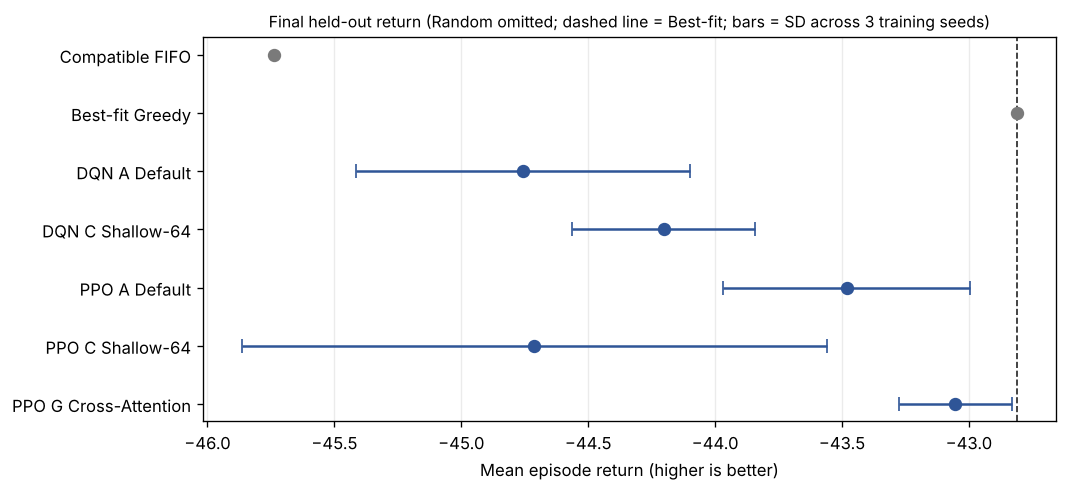

In [39]:
final_overall = recorded_table("final_overall")
final_model_seeds = recorded_table("final_model_seeds")
display(final_overall[["policy_name", "episodes", "mean_return",
    "sample_sd_across_training_seeds_return", "fixed_policy_episode_sd_return",
    "mean_wait_ticks", "mean_lost_rate", "mean_served_rate",
    "mean_seat_utilisation", "mean_table_utilisation", "mean_drain_ticks"]])
display(final_model_seeds[["policy_name", "training_seed", "episodes", "mean_return",
                          "mean_wait_ticks", "mean_lost_rate", "mean_served_rate"]])
# Random-valid (about -62.8) is far below every other policy, so it is listed in the
# table above but left off this zoomed plot to make the learned-agent differences visible.
plot_rows = final_overall[final_overall["policy_id"] != "Random-valid"].reset_index(drop=True)
best_fit = final_overall.loc[final_overall["policy_id"] == "Best-fit Greedy", "mean_return"].item()
fig, ax = plt.subplots(figsize=(9, 4.2))
for y, (_, row) in enumerate(plot_rows.iterrows()):
    spread = row["sample_sd_across_training_seeds_return"]
    learned = row["policy_group"] == "learned"
    ax.errorbar(row["mean_return"], y, xerr=None if pd.isna(spread) else spread,
                fmt="o", markersize=7, capsize=4, color="#2f5597" if learned else "#7a7a7a")
ax.axvline(best_fit, color="#222222", linestyle="--", linewidth=1)
ax.set_yticks(range(len(plot_rows)), plot_rows["policy_name"])
ax.invert_yaxis()
ax.set_xlabel("Mean episode return (higher is better)")
ax.set_title("Final held-out return (Random omitted; dashed line = Best-fit; bars = SD across 3 training seeds)",
             fontsize=9.5)
ax.grid(axis="x", alpha=.25)
fig.tight_layout()
plt.show()


### Paired comparisons against Best-fit

These stored differences pair policies on the same scenario and evaluation seed. Positive return differences favour the learned policy.


In [40]:
paired_architectures = recorded_table("paired_architectures")
paired_models = recorded_table("paired_models")
display(paired_architectures)
display(paired_models)


,policy_id,policy_name,algorithm,architecture_code,training_seed_models,paired_episodes,mean_paired_delta_return,sample_sd_model_mean_delta_return,better_count,better_percent,same_count,same_percent,worse_count,worse_percent
0,DQN_A,DQN A Default,DQN,A,3,2400,-1.9462,0.6581,788,32.8333,453,18.8750,1159,48.2917
1,DQN_C,DQN C Shallow-64,DQN,C,3,2400,-1.3920,0.3608,669,27.8750,663,27.6250,1068,44.5000
2,PPO_A,PPO A Default,PPO,A,3,2400,-0.6713,0.4861,272,11.3333,1506,62.7500,622,25.9167
3,PPO_C,PPO C Shallow-64,PPO,C,3,2400,-1.9025,1.1534,446,18.5833,793,33.0417,1161,48.3750
4,PPO_G,PPO G Cross-Attention,PPO,G,3,2400,-0.2439,0.2215,184,7.6667,1863,77.6250,353,14.7083


,policy_id,policy_name,algorithm,architecture_code,training_seed,paired_episodes,mean_paired_delta_return,better_count,better_percent,same_count,same_percent,worse_count,worse_percent
0,DQN_A,DQN A Default,DQN,A,31000,800,-2.7055,252,31.5000,123,15.3750,425,53.1250
1,DQN_A,DQN A Default,DQN,A,31001,800,-1.5419,266,33.2500,174,21.7500,360,45.0000
2,DQN_A,DQN A Default,DQN,A,31002,800,-1.5911,270,33.7500,156,19.5000,374,46.7500
3,DQN_C,DQN C Shallow-64,DQN,C,31000,800,-1.3658,215,26.8750,248,31.0000,337,42.1250
4,DQN_C,DQN C Shallow-64,DQN,C,31001,800,-1.0450,197,24.6250,275,34.3750,328,41.0000
5,DQN_C,DQN C Shallow-64,DQN,C,31002,800,-1.7651,257,32.1250,140,17.5000,403,50.3750
6,PPO_A,PPO A Default,PPO,A,31000,800,-1.1909,85,10.6250,465,58.1250,250,31.2500
7,PPO_A,PPO A Default,PPO,A,31001,800,-0.5954,104,13.0000,474,59.2500,222,27.7500
8,PPO_A,PPO A Default,PPO,A,31002,800,-0.2276,83,10.3750,567,70.8750,150,18.7500
9,PPO_C,PPO C Shallow-64,PPO,C,31000,800,-1.3294,195,24.3750,187,23.3750,418,52.2500


### Scenario results

The plot subtracts Best-fit within each demand scenario. Negative bars mean lower return than Best-fit in that scenario.


,policy_name,scenario,episodes,mean_return,sample_sd_across_training_seeds_return
0,Random-valid,off_peak,200,-22.0985,NaN
1,Random-valid,normal,200,-47.7935,NaN
2,Random-valid,peak,200,-72.6265,NaN
3,Random-valid,super_peak,200,-108.5780,NaN
4,Compatible FIFO,off_peak,200,-11.7880,NaN
5,Compatible FIFO,normal,200,-30.3285,NaN
6,Compatible FIFO,peak,200,-53.0170,NaN
7,Compatible FIFO,super_peak,200,-87.8230,NaN
8,Best-fit Greedy,off_peak,200,-11.6000,NaN
9,Best-fit Greedy,normal,200,-29.4020,NaN


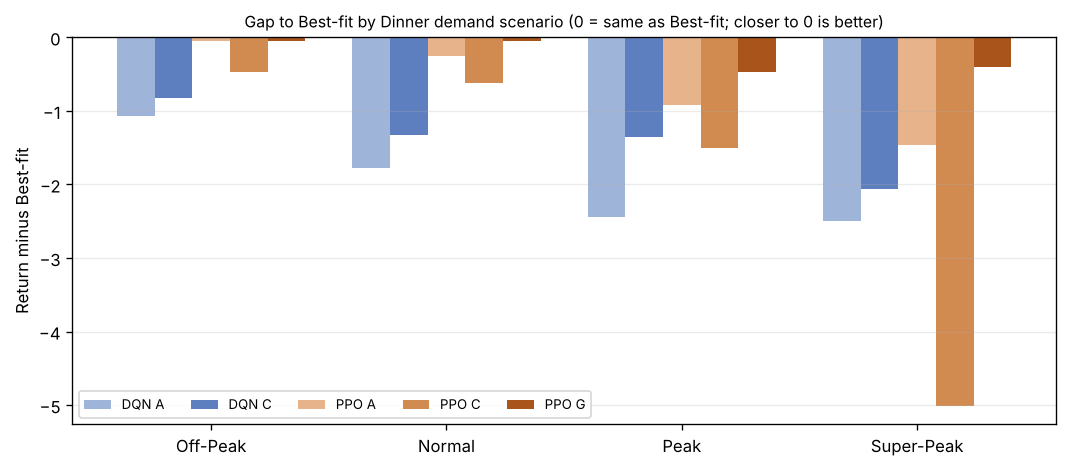

,policy_name,mean_return,sample_sd_across_training_seeds_return
27,PPO C Shallow-64,-85.8503,5.2750
31,PPO G Cross-Attention,-81.2473,0.4916


In [41]:
final_scenarios = recorded_table("final_scenarios")
display(final_scenarios[["policy_name", "scenario", "episodes", "mean_return",
                         "sample_sd_across_training_seeds_return"]])
scenario_order = ["off_peak", "normal", "peak", "super_peak"]
scenario_labels = ["Off-Peak", "Normal", "Peak", "Super-Peak"]
bf = (final_scenarios[final_scenarios["policy_id"] == "Best-fit Greedy"]
      .set_index("scenario").loc[scenario_order, "mean_return"].to_numpy())
agents = ["DQN_A", "DQN_C", "PPO_A", "PPO_C", "PPO_G"]
colors = {"DQN_A": "#9fb4d9", "DQN_C": "#5d7fbf", "PPO_A": "#e6b38a", "PPO_C": "#d18a4f", "PPO_G": "#a8541b"}
labels = {"DQN_A": "DQN A", "DQN_C": "DQN C", "PPO_A": "PPO A", "PPO_C": "PPO C", "PPO_G": "PPO G"}
width = 0.16
fig, ax = plt.subplots(figsize=(9, 4))
# Subtract the Best-fit mean within each scenario to show the performance gap.
for k, pid in enumerate(agents):
    group = final_scenarios[final_scenarios["policy_id"] == pid].set_index("scenario").loc[scenario_order]
    xs = [i + (k - 2) * width for i in range(len(scenario_order))]
    ax.bar(xs, group["mean_return"].to_numpy() - bf, width, color=colors[pid], label=labels[pid])
ax.axhline(0, color="#222222", linewidth=1)
ax.set_xticks(range(len(scenario_order)), scenario_labels)
ax.set_ylabel("Return minus Best-fit")
ax.set_title("Gap to Best-fit by Dinner demand scenario (0 = same as Best-fit; closer to 0 is better)",
             fontsize=9.5)
ax.legend(ncol=5, fontsize=8, loc="lower left")
ax.grid(axis="y", alpha=.25)
fig.tight_layout()
plt.show()
super_peak = final_scenarios[(final_scenarios["algorithm"] == "PPO") &
                            (final_scenarios["scenario"] == "super_peak") &
                            (final_scenarios["architecture_code"].isin(["C", "G"]))]
display(super_peak[["policy_name", "mean_return", "sample_sd_across_training_seeds_return"]])


### Preregistered comparisons

The stored comparisons are DQN C versus A, PPO G versus A, and PPO G versus C.
Positive delta_return means the challenger had a higher mean return.
These are descriptive comparisons; the notebook adds no significance claim.

In [42]:
preregistered = recorded_table("preregistered")
display(preregistered[["comparison_id", "scope", "training_seed", "challenger", "reference",
                      "delta_return", "sample_sd_delta_return",
                      "delta_wait_ticks", "delta_lost_rate", "delta_served_rate"]])


,comparison_id,scope,training_seed,challenger,reference,delta_return,sample_sd_delta_return,delta_wait_ticks,delta_lost_rate,delta_served_rate
0,DQN_C_vs_A,training_seed,31000.0000,DQN C Shallow-64,DQN A Default,1.3398,NaN,-0.0701,-0.0037,0.0037
1,DQN_C_vs_A,training_seed,31001.0000,DQN C Shallow-64,DQN A Default,0.4969,NaN,-0.0232,-0.0031,0.0031
2,DQN_C_vs_A,training_seed,31002.0000,DQN C Shallow-64,DQN A Default,-0.1740,NaN,0.0078,0.0007,-0.0007
3,DQN_C_vs_A,aggregate_across_training_seeds,NaN,DQN C Shallow-64,DQN A Default,0.5542,0.7585,-0.0285,-0.0020,0.0020
4,PPO_G_vs_A,training_seed,31000.0000,PPO G Cross-Attention,PPO A Default,0.7578,NaN,0.0126,-0.0056,0.0056
5,PPO_G_vs_A,training_seed,31001.0000,PPO G Cross-Attention,PPO A Default,0.2971,NaN,-0.0008,-0.0008,0.0008
6,PPO_G_vs_A,training_seed,31002.0000,PPO G Cross-Attention,PPO A Default,0.2274,NaN,0.0004,-0.0016,0.0016
7,PPO_G_vs_A,aggregate_across_training_seeds,NaN,PPO G Cross-Attention,PPO A Default,0.4274,0.2882,0.0041,-0.0026,0.0026
8,PPO_G_vs_C,training_seed,31000.0000,PPO G Cross-Attention,PPO C Shallow-64,0.8963,NaN,-0.0410,-0.0035,0.0035
9,PPO_G_vs_C,training_seed,31001.0000,PPO G Cross-Attention,PPO C Shallow-64,2.9320,NaN,-0.1304,-0.0059,0.0059


## K. Interpretation and limitations

- Best-fit remained the strongest mean-return policy (-42.8098). PPO G was the
  strongest learned architecture (-43.0536), closely approaching Best-fit while
  remaining below it on overall mean return.
- PPO G performed better than the tested PPO A and C alternatives in the final
  held-out evaluation. The earlier F2–G validation comparison is consistent with
  a possible benefit from explicit party-to-table interaction, but it does not
  prove that attention itself caused the improvement.
- PPO C had high training-seed variability under Super-Peak demand (SD approximately
  5.28), whereas PPO G was much more stable in this evaluation (SD approximately
  0.49). This is descriptive evidence from three training seeds, not a significance
  claim.
- The fixed 102,400-step budget and the training-sufficiency audit remain
  limitations. Final results were accepted as observed; no final-test reselection
  or further tuning is proposed.
- Architecture development used a small fixed validation population. The final
  population was separate. DQN-versus-PPO comparisons change the algorithm as well
  as architecture and are not clean architecture ablations.
- The frozen evaluator did not provide complete party-size outcomes. No new
  party-size performance claim or decision-level action-agreement result is added.
- The demonstration output above describes one development episode.
  It is not an estimate of general performance and is not inserted into any
  formal comparison.
- This notebook embeds the core implementation and the recorded result tables. The
  submission includes tests and selected checkpoints. The external project archive
  keeps raw training runs, checkpoint history and evaluation scripts.

### Reproducibility and acknowledgements

Core definitions match the accompanying restaurant_rl modules.
Repository imports were replaced by shared notebook names. The constructor
dispatcher, demonstration metric helper and disabled training recipe are
notebook presentation code. The embedded CSV text preserves the recorded values;
display rounding and figures do not modify that data.

Stable-Baselines3 supplies DQN and sb3-contrib supplies MaskablePPO; their internals
are not copied. PyTorch, Gymnasium, NumPy, pandas and matplotlib support execution
and presentation.


## L. References and Generative AI acknowledgement

Huang, S. & Ontañón, S. 2022, ‘A closer look at invalid action masking in policy gradient algorithms’, *The International FLAIRS Conference Proceedings*, vol. 35.

Leurent, E. & Mercat, J. 2019, ‘Social attention for autonomous decision-making in dense traffic’, arXiv preprint arXiv:1911.12250.

Mnih, V., Kavukcuoglu, K., Silver, D. et al. 2015, ‘Human-level control through deep reinforcement learning’, *Nature*, vol. 518, no. 7540, pp. 529–533.

Raffin, A., Hill, A., Gleave, A., Kanervisto, A., Ernestus, M. & Dormann, N. 2021, ‘Stable-Baselines3: reliable reinforcement learning implementations’, *Journal of Machine Learning Research*, vol. 22, no. 268, pp. 1–8.

Schulman, J., Wolski, F., Dhariwal, P., Radford, A. & Klimov, O. 2017, ‘Proximal policy optimization algorithms’, arXiv preprint arXiv:1707.06347.

Sutton, R.S. & Barto, A.G. 2018, *Reinforcement learning: an introduction*, 2nd edn, MIT Press, Cambridge, MA.

Towers, M., Kwiatkowski, A., Terry, J. et al. 2024, ‘Gymnasium: a standard interface for reinforcement learning environments’, arXiv preprint arXiv:2407.17032.

Vaswani, A., Shazeer, N., Parmar, N., Uszkoreit, J., Jones, L., Gomez, A.N., Kaiser, Ł. & Polosukhin, I. 2017, ‘Attention is all you need’, *Advances in Neural Information Processing Systems*, vol. 30, pp. 5998–6008.

### Generative AI acknowledgement

Generative AI tools were used to assist with code debugging, documentation, grammar and clarity, and visual/presentation planning, including assembling this executable notebook from the project code. Architecture choices, environment design decisions, experimental results, numerical values and final interpretations were reviewed by the team against the project source files and recorded result files. AI assistance does not replace the team's responsibility to understand and defend the submitted work.


In [43]:
assert RUN_FULL_TRAINING is False
assert demo_result["completed_episode"] and not demo_result["truncated"]
assert parameter_verification["Matches formal counts"].all()
assert len(validation_view) == 20 and len(final_overall) == 8
assert len(roster[roster["policy_group"] == "learned"]) == 15
print("Run All complete: one development demonstration and 20 construction checks.")
print("Formal tables and figures display embedded recorded outputs.")
print("Full training remains disabled; no frozen final episode was requested.")


Run All complete: one development demonstration and 20 construction checks.
Formal tables and figures display embedded recorded outputs.
Full training remains disabled; no frozen final episode was requested.
